Step 1 Upload the dataset.

Inspect the actual populated data

In [2]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("HHS_Unaccompanied_Alien_Children_Program (1).csv")

# Basic information
print("Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Shape: (1170, 6)

Column Names:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']

Data Types:
Date                                                object
Children apprehended and placed in CBP custody*    float64
Children in CBP custody                            float64
Children transferred out of CBP custody            float64
Children in HHS Care                                object
Children discharged from HHS Care                  float64
dtype: object

First 5 rows:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0



Last 5 rows:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
1165,NaN,NaN,NaN,NaN,NaN,NaN
1166,NaN,NaN,NaN,NaN,NaN,NaN
1167,NaN,NaN,NaN,NaN,NaN,NaN
1168,NaN,NaN,NaN,NaN,NaN,NaN
1169,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
Date                                               450
Children apprehended and placed in CBP custody*    450
Children in CBP custody                            450
Children transferred out of CBP custody            450
Children in HHS Care                               450
Children discharged from HHS Care                  450
dtype: int64

Duplicate Rows: 449


In [3]:
# Check how many completely empty rows exist
empty_rows = df.isna().all(axis=1).sum()

print("Completely empty rows:", empty_rows)

# Remove ONLY completely empty rows for inspection
df_clean = df.dropna(how="all").copy()

print("Rows after removing completely empty rows:", len(df_clean))

# Check duplicate rows again
print("Duplicate rows after removing empty rows:", df_clean.duplicated().sum())

# Show the last 10 actual records
display(df_clean.tail(10))

Completely empty rows: 450
Rows after removing completely empty rows: 720
Duplicate rows after removing empty rows: 0


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
710,"February 02, 2023",15.0,13.0,23.0,"7,879",298.0
711,"February 01, 2023",25.0,32.0,27.0,"7,903",231.0
712,"January 31, 2023",26.0,36.0,36.0,"7,803",158.0
713,"January 30, 2023",34.0,54.0,29.0,"7,743",196.0
714,"January 29, 2023",23.0,45.0,11.0,"7,472",303.0
715,"January 25, 2023",20.0,22.0,41.0,"7,538",180.0
716,"January 24, 2023",47.0,42.0,47.0,"7,433",175.0
717,"January 23, 2023",32.0,50.0,39.0,"7,280",181.0
718,"January 22, 2023",32.0,49.0,39.0,"7,122",227.0
719,"January 12, 2023",33.0,53.0,34.0,"6,566",436.0


In [4]:
# Convert Date to datetime
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")

print("Earliest date:", df_clean["Date"].min())
print("Latest date:", df_clean["Date"].max())

print("\nNumber of invalid dates:", df_clean["Date"].isna().sum())

# Sort chronologically
df_clean = df_clean.sort_values("Date").reset_index(drop=True)

display(df_clean.head())
display(df_clean.tail())

Earliest date: 2023-01-12 00:00:00
Latest date: 2025-12-21 00:00:00

Number of invalid dates: 0


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,33.0,53.0,34.0,"6,566",436.0
1,2023-01-22,32.0,49.0,39.0,"7,122",227.0
2,2023-01-23,32.0,50.0,39.0,"7,280",181.0
3,2023-01-24,47.0,42.0,47.0,"7,433",175.0
4,2023-01-25,20.0,22.0,41.0,"7,538",180.0


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
715,2025-12-15,11.0,42.0,9.0,"2,470",7.0
716,2025-12-16,8.0,54.0,15.0,"2,468",9.0
717,2025-12-17,7.0,31.0,11.0,"2,481",10.0
718,2025-12-18,11.0,50.0,6.0,"2,472",16.0
719,2025-12-21,6.0,18.0,11.0,"2,484",14.0


In [5]:
duplicate_dates = df_clean[df_clean["Date"].duplicated(keep=False)]

print("Number of rows with duplicate dates:", len(duplicate_dates))

if len(duplicate_dates) > 0:
    display(duplicate_dates)

Number of rows with duplicate dates: 0


Step 2 — Clean and standardize the raw dataset

In [6]:
# Make a copy of the raw dataset
df_clean = df.copy()

# --------------------------------------------------
# 1. Remove completely empty rows
# --------------------------------------------------
df_clean = df_clean.dropna(how="all").copy()

print("Rows after removing empty rows:", len(df_clean))

# --------------------------------------------------
# 2. Convert Date to datetime
# --------------------------------------------------
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    errors="coerce"
)

# --------------------------------------------------
# 3. Clean HHS Care column
# --------------------------------------------------
df_clean["Children in HHS Care"] = (
    df_clean["Children in HHS Care"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

df_clean["Children in HHS Care"] = pd.to_numeric(
    df_clean["Children in HHS Care"],
    errors="coerce"
)

# --------------------------------------------------
# 4. Sort chronologically
# --------------------------------------------------
df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# --------------------------------------------------
# 5. Check duplicate dates
# --------------------------------------------------
duplicate_dates = df_clean["Date"].duplicated().sum()

# --------------------------------------------------
# 6. Display data quality summary
# --------------------------------------------------
print("\n--- DATA QUALITY SUMMARY ---")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))
print("Earliest date:", df_clean["Date"].min())
print("Latest date:", df_clean["Date"].max())
print("Duplicate dates:", duplicate_dates)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nFirst 5 chronological records:")
display(df_clean.head())

print("\nLast 5 chronological records:")
display(df_clean.tail())

Rows after removing empty rows: 720

--- DATA QUALITY SUMMARY ---
Rows: 720
Columns: 6
Earliest date: 2023-01-12 00:00:00
Latest date: 2025-12-21 00:00:00
Duplicate dates: 0

Missing values:
Date                                               0
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64

Data types:
Date                                               datetime64[ns]
Children apprehended and placed in CBP custody*           float64
Children in CBP custody                                   float64
Children transferred out of CBP custody                   float64
Children in HHS Care                                        int64
Children discharged from HHS Care                         float64
dtype: object

First 5 chronological records:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,33.0,53.0,34.0,6566,436.0
1,2023-01-22,32.0,49.0,39.0,7122,227.0
2,2023-01-23,32.0,50.0,39.0,7280,181.0
3,2023-01-24,47.0,42.0,47.0,7433,175.0
4,2023-01-25,20.0,22.0,41.0,7538,180.0



Last 5 chronological records:


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
715,2025-12-15,11.0,42.0,9.0,2470,7.0
716,2025-12-16,8.0,54.0,15.0,2468,9.0
717,2025-12-17,7.0,31.0,11.0,2481,10.0
718,2025-12-18,11.0,50.0,6.0,2472,16.0
719,2025-12-21,6.0,18.0,11.0,2484,14.0


Step 3 — Validate the operational logic

In [7]:
# ============================================
# STEP 3: DATA VALIDATION
# ============================================

# Check 1: Transfers should not exceed CBP custody
transfer_violations = df_clean[
    df_clean["Children transferred out of CBP custody"]
    > df_clean["Children in CBP custody"]
].copy()

# Check 2: Discharges should not exceed HHS care
discharge_violations = df_clean[
    df_clean["Children discharged from HHS Care"]
    > df_clean["Children in HHS Care"]
].copy()

print("Transfers > CBP custody:", len(transfer_violations))
print("Discharges > HHS care:", len(discharge_violations))

# Display violations if any exist
if len(transfer_violations) > 0:
    print("\n--- Transfer Violations ---")
    display(transfer_violations)

if len(discharge_violations) > 0:
    print("\n--- Discharge Violations ---")
    display(discharge_violations)

Transfers > CBP custody: 86
Discharges > HHS care: 0

--- Transfer Violations ---


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
3,2023-01-24,47.0,42.0,47.0,7433,175.0
4,2023-01-25,20.0,22.0,41.0,7538,180.0
9,2023-02-02,15.0,13.0,23.0,7879,298.0
22,2023-02-22,107.0,215.0,230.0,7978,232.0
23,2023-02-23,101.0,162.0,178.0,7914,386.0
...,...,...,...,...,...,...
502,2025-01-30,47.0,42.0,47.0,3923,159.0
503,2025-02-02,20.0,22.0,41.0,3483,168.0
508,2025-02-09,15.0,13.0,23.0,2878,99.0
512,2025-02-13,15.0,10.0,23.0,2703,72.0


In [8]:
# ============================================
# BASIC NUMERICAL VALIDATION
# ============================================

numeric_columns = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care"
]

print("Negative values:")
for col in numeric_columns:
    count = (df_clean[col] < 0).sum()
    print(f"{col}: {count}")

print("\nMissing values:")
print(df_clean[numeric_columns].isnull().sum())

print("\nSummary statistics:")
display(df_clean[numeric_columns].describe().T)

Negative values:
Children apprehended and placed in CBP custody*: 0
Children in CBP custody: 0
Children transferred out of CBP custody: 0
Children in HHS Care: 0
Children discharged from HHS Care: 0

Missing values:
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Children apprehended and placed in CBP custody*,720.0,93.523611,72.646625,0.0,12.00,99.0,147.25,333.0
Children in CBP custody,720.0,171.494444,126.354965,7.0,36.00,193.0,263.25,531.0
Children transferred out of CBP custody,720.0,128.668056,97.322012,0.0,14.00,157.0,199.25,440.0
Children in HHS Care,720.0,6061.275000,2833.070109,1972.0,2467.75,6406.5,8010.25,11516.0
Children discharged from HHS Care,720.0,173.406944,125.702841,0.0,19.75,181.0,267.00,505.0


Step 4 — Create the project's core metrics

In [9]:
# ============================================
# STEP 4: DERIVED HEALTHCARE CAPACITY METRICS
# ============================================

# Total children currently under the combined CBP + HHS system
df_clean["Total System Load"] = (
    df_clean["Children in CBP custody"]
    + df_clean["Children in HHS Care"]
)

# Net intake pressure into HHS
# Positive = more children transferred in than discharged
# Negative = more children discharged than transferred in
df_clean["Net Intake Pressure"] = (
    df_clean["Children transferred out of CBP custody"]
    - df_clean["Children discharged from HHS Care"]
)

# Day-over-day percentage change in total system load
df_clean["Care Load Growth Rate"] = (
    df_clean["Total System Load"]
    .pct_change() * 100
)

# 7-day rolling average
df_clean["7-Day Rolling Load"] = (
    df_clean["Total System Load"]
    .rolling(window=7)
    .mean()
)

# 14-day rolling average
df_clean["14-Day Rolling Load"] = (
    df_clean["Total System Load"]
    .rolling(window=14)
    .mean()
)

# Cumulative net intake pressure
df_clean["Cumulative Net Intake"] = (
    df_clean["Net Intake Pressure"].cumsum()
)

# Discharge offset ratio
# Measures discharges relative to transfers into HHS
df_clean["Discharge Offset Ratio"] = np.where(
    df_clean["Children transferred out of CBP custody"] > 0,
    df_clean["Children discharged from HHS Care"]
    / df_clean["Children transferred out of CBP custody"],
    np.nan
)

# Display results
display(
    df_clean[
        [
            "Date",
            "Children in CBP custody",
            "Children transferred out of CBP custody",
            "Children in HHS Care",
            "Children discharged from HHS Care",
            "Total System Load",
            "Net Intake Pressure",
            "Care Load Growth Rate",
            "7-Day Rolling Load",
            "14-Day Rolling Load",
            "Cumulative Net Intake",
            "Discharge Offset Ratio"
        ]
    ].head(20)
)

,Date,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Total System Load,Net Intake Pressure,Care Load Growth Rate,7-Day Rolling Load,14-Day Rolling Load,Cumulative Net Intake,Discharge Offset Ratio
0,2023-01-12,53.0,34.0,6566,436.0,6619.0,-402.0,NaN,NaN,NaN,-402.0,12.823529
1,2023-01-22,49.0,39.0,7122,227.0,7171.0,-188.0,8.339628,NaN,NaN,-590.0,5.820513
2,2023-01-23,50.0,39.0,7280,181.0,7330.0,-142.0,2.217264,NaN,NaN,-732.0,4.641026
3,2023-01-24,42.0,47.0,7433,175.0,7475.0,-128.0,1.978172,NaN,NaN,-860.0,3.723404
4,2023-01-25,22.0,41.0,7538,180.0,7560.0,-139.0,1.137124,NaN,NaN,-999.0,4.390244
5,2023-01-29,45.0,11.0,7472,303.0,7517.0,-292.0,-0.568783,NaN,NaN,-1291.0,27.545455
6,2023-01-30,54.0,29.0,7743,196.0,7797.0,-167.0,3.724890,7352.714286,NaN,-1458.0,6.758621
7,2023-01-31,36.0,36.0,7803,158.0,7839.0,-122.0,0.538669,7527.000000,NaN,-1580.0,4.388889
8,2023-02-01,32.0,27.0,7903,231.0,7935.0,-204.0,1.224646,7636.142857,NaN,-1784.0,8.555556
9,2023-02-02,13.0,23.0,7879,298.0,7892.0,-275.0,-0.541903,7716.428571,NaN,-2059.0,12.956522


Step 5 — Exploratory Data Analysis (EDA)

Step 5A — Total System Load over time

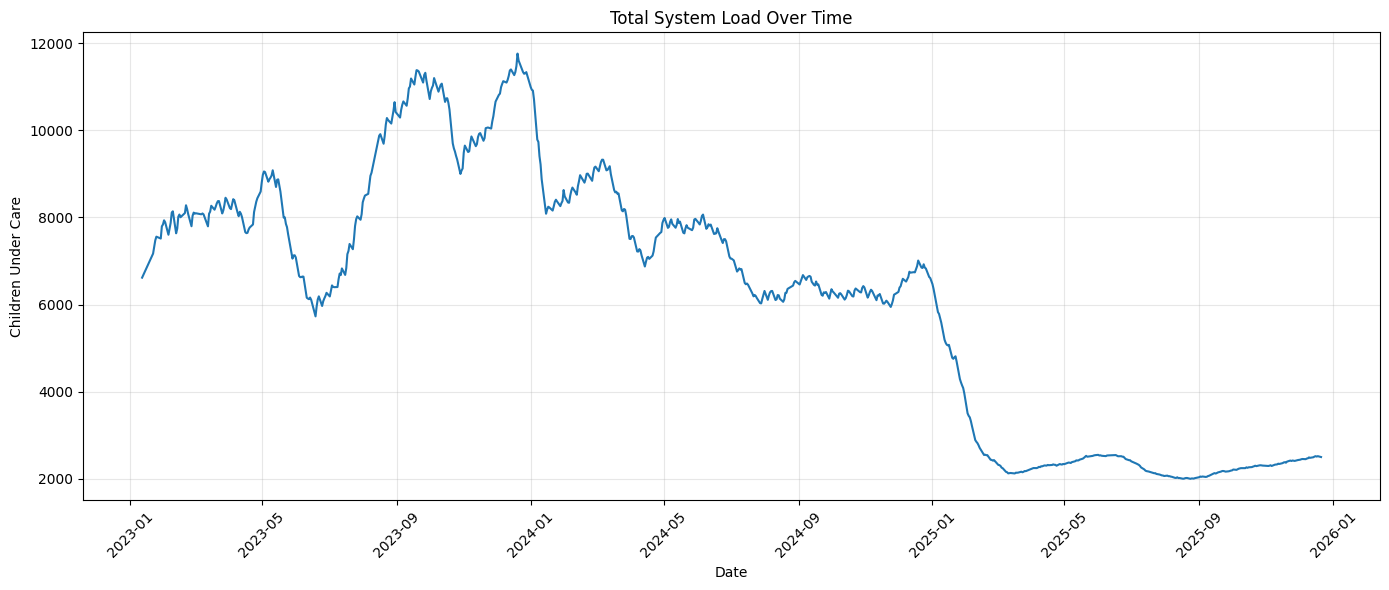

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Total System Load"]
)

plt.title("Total System Load Over Time")
plt.xlabel("Date")
plt.ylabel("Children Under Care")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 5B — CBP vs HHS Care Load

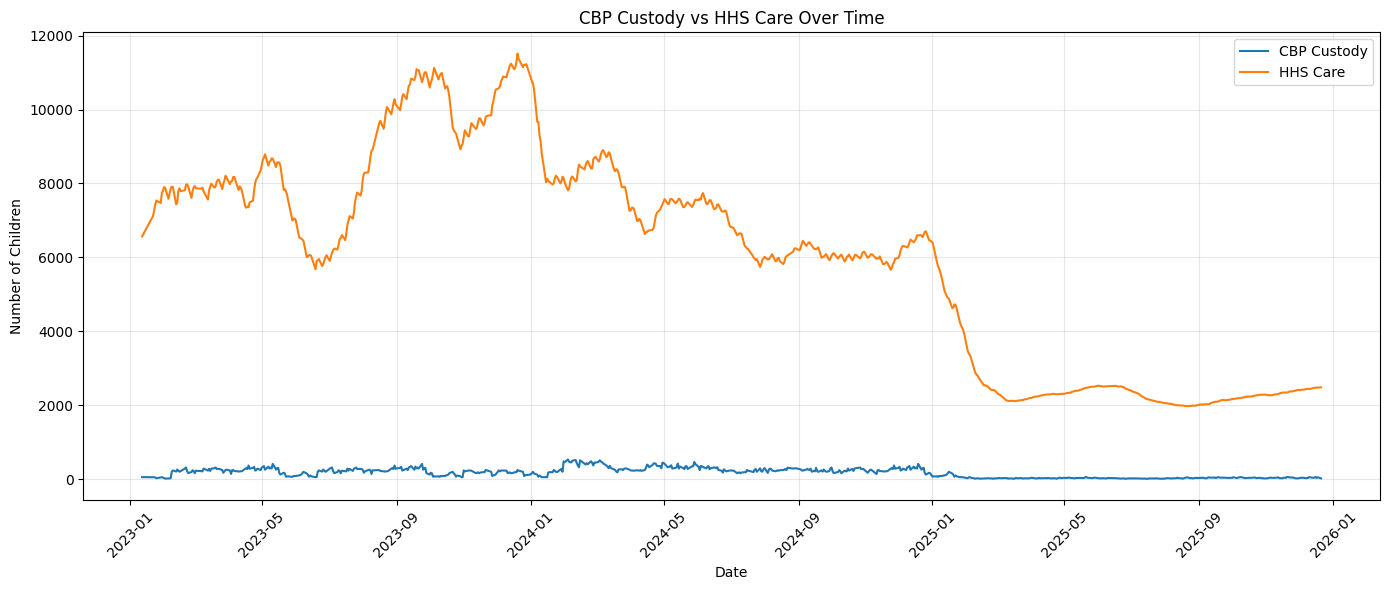

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children in CBP custody"],
    label="CBP Custody"
)

plt.plot(
    df_clean["Date"],
    df_clean["Children in HHS Care"],
    label="HHS Care"
)

plt.title("CBP Custody vs HHS Care Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 5C — Transfers vs Discharges

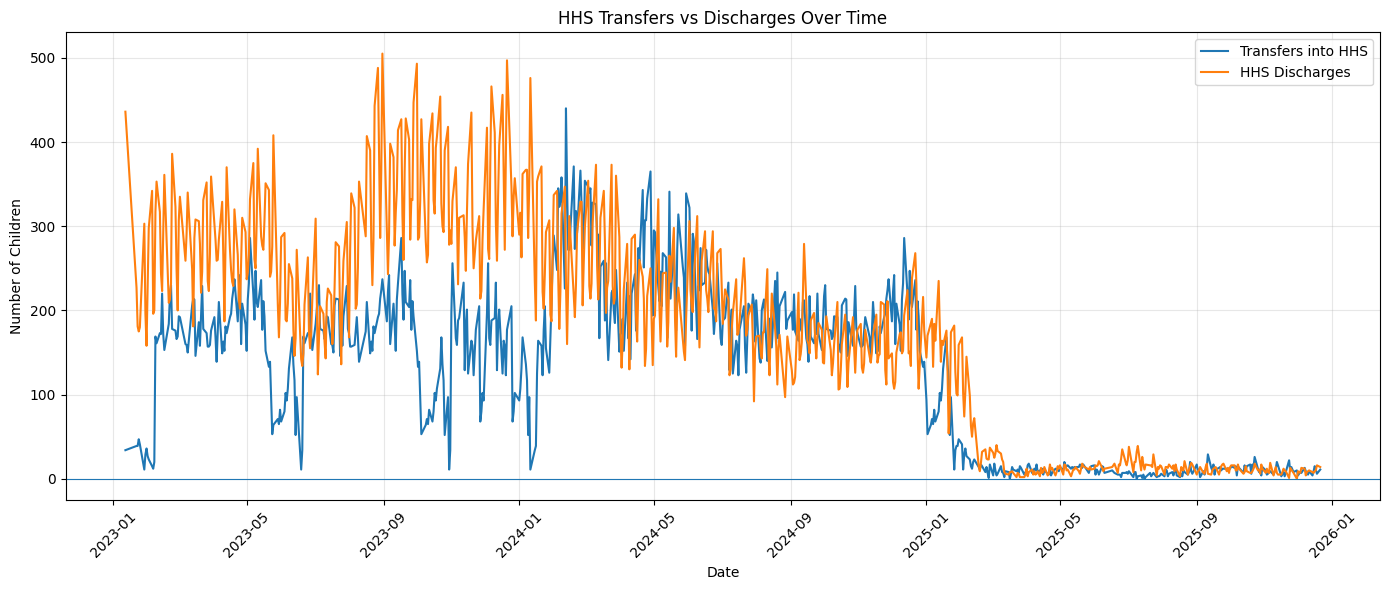

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children transferred out of CBP custody"],
    label="Transfers into HHS"
)

plt.plot(
    df_clean["Date"],
    df_clean["Children discharged from HHS Care"],
    label="HHS Discharges"
)

plt.axhline(
    y=0,
    linewidth=0.8
)

plt.title("HHS Transfers vs Discharges Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 5D — Net Intake Pressure

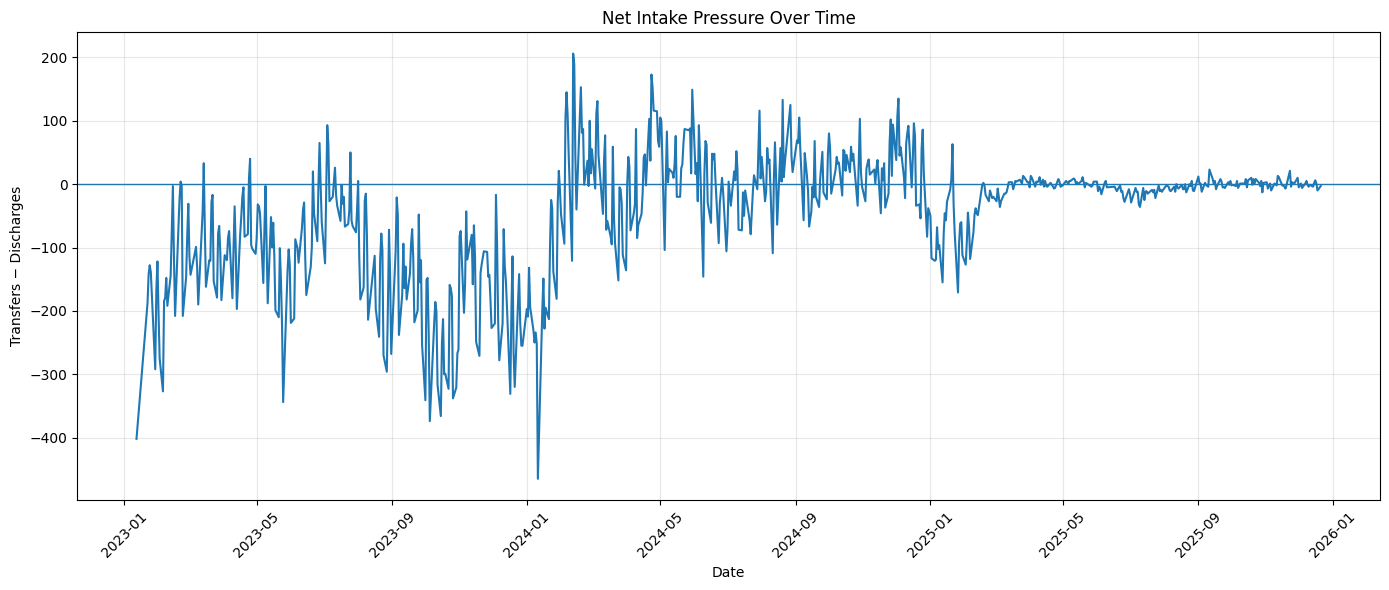

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Net Intake Pressure"]
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title("Net Intake Pressure Over Time")
plt.xlabel("Date")
plt.ylabel("Transfers − Discharges")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 5E — Rolling averages

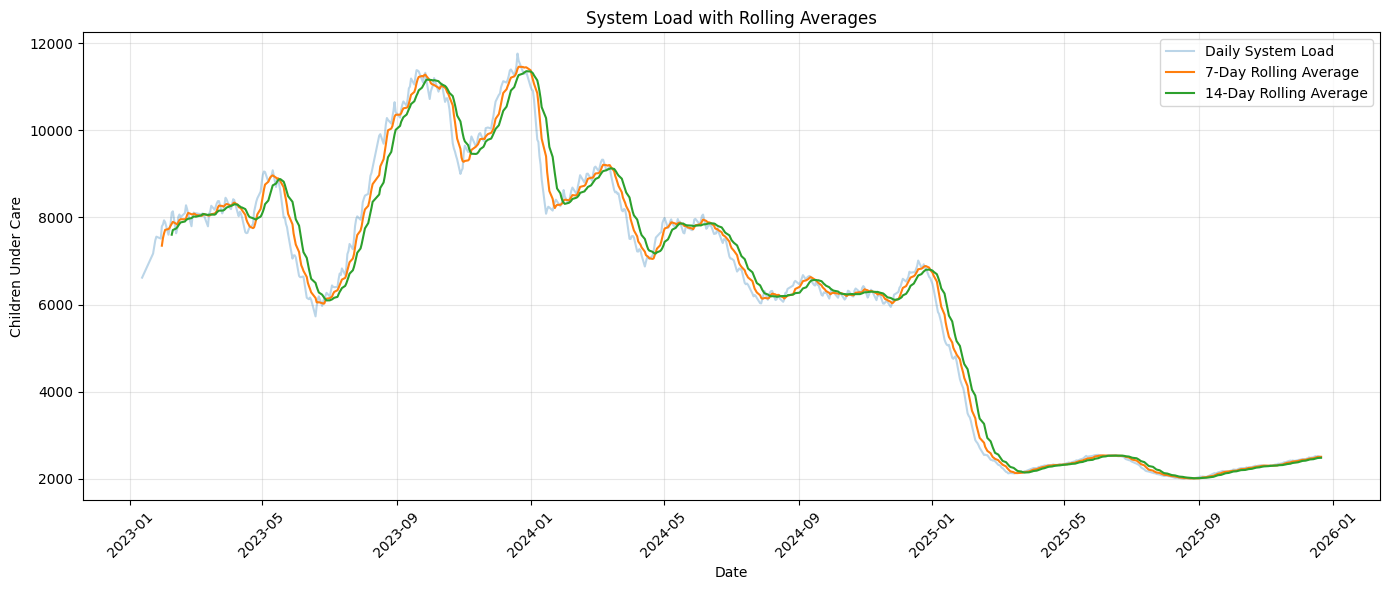

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Total System Load"],
    alpha=0.3,
    label="Daily System Load"
)

plt.plot(
    df_clean["Date"],
    df_clean["7-Day Rolling Load"],
    label="7-Day Rolling Average"
)

plt.plot(
    df_clean["Date"],
    df_clean["14-Day Rolling Load"],
    label="14-Day Rolling Average"
)

plt.title("System Load with Rolling Averages")
plt.xlabel("Date")
plt.ylabel("Children Under Care")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 5F — Monthly analysis

In [15]:
# Create month column
df_clean["Month"] = df_clean["Date"].dt.to_period("M")

monthly = (
    df_clean
    .groupby("Month")
    .agg(
        Average_System_Load=("Total System Load", "mean"),
        Maximum_System_Load=("Total System Load", "max"),
        Average_Net_Intake=("Net Intake Pressure", "mean"),
        Total_Transfers=("Children transferred out of CBP custody", "sum"),
        Total_Discharges=("Children discharged from HHS Care", "sum")
    )
    .reset_index()
)

monthly["Month"] = monthly["Month"].astype(str)

display(monthly)

,Month,Average_System_Load,Maximum_System_Load,Average_Net_Intake,Total_Transfers,Total_Discharges
0,2023-01,7413.500000,7839.0,-197.500000,276.0,1856.0
1,2023-02,7967.105263,8281.0,-134.000000,2637.0,5183.0
2,2023-03,8190.473684,8453.0,-104.000000,3399.0,5375.0
3,2023-04,8092.857143,8595.0,-81.000000,3967.0,5668.0
4,2023-05,8404.090909,9084.0,-119.727273,3622.0,6256.0
5,2023-06,6282.100000,7084.0,-80.650000,2416.0,4029.0
6,2023-07,7073.380952,8076.0,-24.285714,3897.0,4407.0
7,2023-08,9585.100000,10647.0,-144.150000,3587.0,6470.0
8,2023-09,10992.368421,11382.0,-135.526316,3971.0,6546.0
9,2023-10,10308.227273,11200.0,-254.954545,2049.0,7658.0


Step 6 — Capacity Pressure & Stress Analysis.

Step 6A — Define high-load periods

In [16]:
# ============================================
# STEP 6A: HIGH-LOAD IDENTIFICATION
# ============================================

load_75th = df_clean["Total System Load"].quantile(0.75)
load_90th = df_clean["Total System Load"].quantile(0.90)

print("75th percentile load:", round(load_75th, 2))
print("90th percentile load:", round(load_90th, 2))

# Create pressure flags
df_clean["High Load"] = (
    df_clean["Total System Load"] >= load_75th
)

df_clean["Very High Load"] = (
    df_clean["Total System Load"] >= load_90th
)

print("\nHigh-load days:", df_clean["High Load"].sum())
print("Very-high-load days:", df_clean["Very High Load"].sum())

75th percentile load: 8249.5
90th percentile load: 9920.9

High-load days: 180
Very-high-load days: 72


Step 6B — Identify sustained pressure

In [17]:
# ============================================
# STEP 6B: SUSTAINED HIGH-LOAD PERIODS
# ============================================

median_load = df_clean["Total System Load"].median()

df_clean["Sustained High Load"] = (
    df_clean["7-Day Rolling Load"] > load_75th
)

print("Median system load:", round(median_load, 2))
print(
    "Days classified as sustained high load:",
    df_clean["Sustained High Load"].sum()
)

Median system load: 6633.5
Days classified as sustained high load: 188


In [18]:
sustained_periods = df_clean[
    df_clean["Sustained High Load"]
][
    [
        "Date",
        "Total System Load",
        "7-Day Rolling Load",
        "Net Intake Pressure"
    ]
]

display(sustained_periods.head(20))

,Date,Total System Load,7-Day Rolling Load,Net Intake Pressure
40,2023-03-23,8378.0,8271.571429,-153.0
41,2023-03-26,8093.0,8265.571429,-179.0
42,2023-03-27,8165.0,8250.714286,-78.0
43,2023-03-28,8288.0,8266.285714,-66.0
44,2023-03-29,8453.0,8296.142857,-108.0
45,2023-03-30,8414.0,8309.285714,-183.0
46,2023-04-02,8213.0,8286.285714,-112.0
47,2023-04-03,8193.0,8259.857143,-116.0
48,2023-04-04,8303.0,8289.857143,-120.0
49,2023-04-05,8420.0,8326.285714,-85.0


Step 6C — Backlog accumulation

In [19]:
# ============================================
# STEP 6C: BACKLOG INDICATOR
# ============================================

df_clean["Backlog Indicator"] = (
    df_clean["Children transferred out of CBP custody"]
    - df_clean["Children discharged from HHS Care"]
).cumsum()

display(
    df_clean[
        [
            "Date",
            "Net Intake Pressure",
            "Backlog Indicator"
        ]
    ].head(20)
)

,Date,Net Intake Pressure,Backlog Indicator
0,2023-01-12,-402.0,-402.0
1,2023-01-22,-188.0,-590.0
2,2023-01-23,-142.0,-732.0
3,2023-01-24,-128.0,-860.0
4,2023-01-25,-139.0,-999.0
5,2023-01-29,-292.0,-1291.0
6,2023-01-30,-167.0,-1458.0
7,2023-01-31,-122.0,-1580.0
8,2023-02-01,-204.0,-1784.0
9,2023-02-02,-275.0,-2059.0


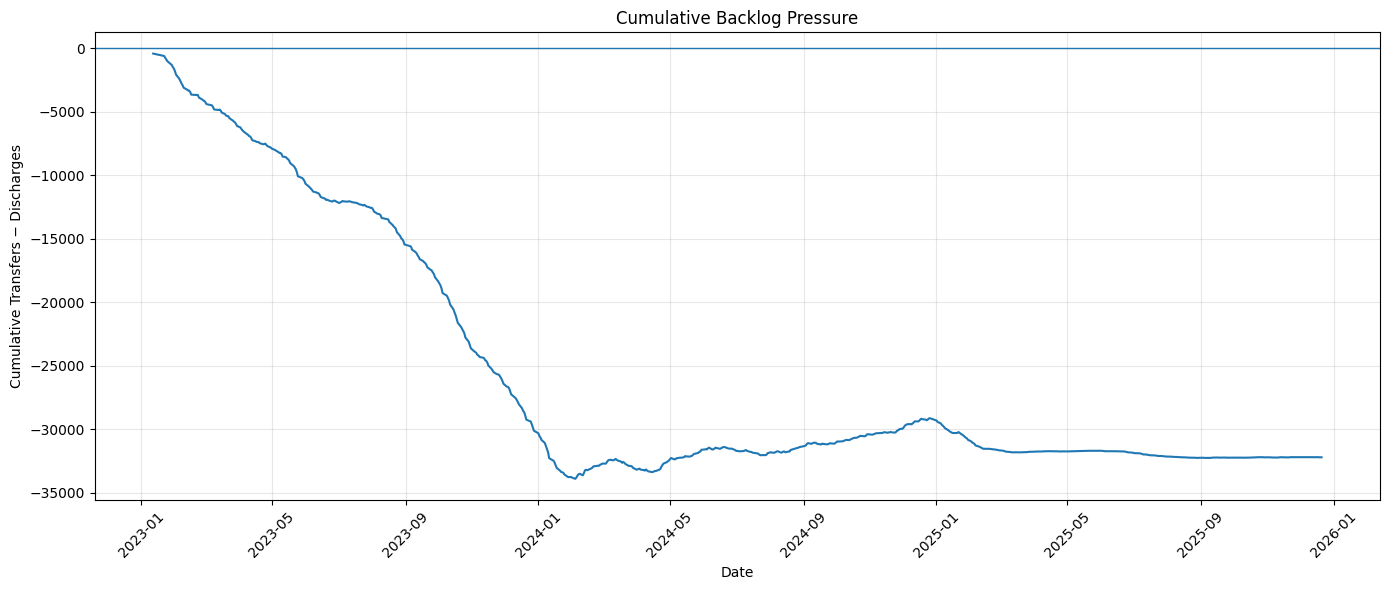

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Backlog Indicator"]
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title("Cumulative Backlog Pressure")
plt.xlabel("Date")
plt.ylabel("Cumulative Transfers − Discharges")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 6D — Care Load Volatility Index

In [21]:
# ============================================
# STEP 6D: CARE LOAD VOLATILITY
# ============================================

mean_load = df_clean["Total System Load"].mean()
std_load = df_clean["Total System Load"].std()

volatility_index = std_load / mean_load

print("Mean System Load:", round(mean_load, 2))
print("Standard Deviation:", round(std_load, 2))
print("Care Load Volatility Index:", round(volatility_index, 4))

Mean System Load: 6232.77
Standard Deviation: 2918.46
Care Load Volatility Index: 0.4682


In [22]:
monthly_volatility = (
    df_clean
    .groupby("Month")["Total System Load"]
    .agg(["mean", "std"])
    .reset_index()
)

monthly_volatility["Volatility Index"] = (
    monthly_volatility["std"]
    / monthly_volatility["mean"]
)

display(monthly_volatility)

,Month,mean,std,Volatility Index
0,2023-01,7413.500000,389.337900,0.052517
1,2023-02,7967.105263,191.054063,0.023980
2,2023-03,8190.473684,159.771145,0.019507
3,2023-04,8092.857143,286.722215,0.035429
4,2023-05,8404.090909,694.483495,0.082636
5,2023-06,6282.100000,324.831276,0.051707
6,2023-07,7073.380952,619.234808,0.087544
7,2023-08,9585.100000,782.574758,0.081645
8,2023-09,10992.368421,337.820006,0.030732
9,2023-10,10308.227273,777.121547,0.075388


Step 6E — Final KPI summary

In [23]:
# ============================================
# STEP 6E: KPI SUMMARY
# ============================================

kpi_summary = {
    "Average Total System Load":
        df_clean["Total System Load"].mean(),

    "Maximum Total System Load":
        df_clean["Total System Load"].max(),

    "Minimum Total System Load":
        df_clean["Total System Load"].min(),

    "Average Net Intake Pressure":
        df_clean["Net Intake Pressure"].mean(),

    "Total Transfers":
        df_clean["Children transferred out of CBP custody"].sum(),

    "Total Discharges":
        df_clean["Children discharged from HHS Care"].sum(),

    "Care Load Volatility Index":
        volatility_index,

    "High Load Days":
        df_clean["High Load"].sum(),

    "Very High Load Days":
        df_clean["Very High Load"].sum(),

    "Final Cumulative Net Intake":
        df_clean["Cumulative Net Intake"].iloc[-1]
}

kpi_df = pd.DataFrame(
    list(kpi_summary.items()),
    columns=["KPI", "Value"]
)

display(kpi_df)

,KPI,Value
0,Average Total System Load,6232.769444
1,Maximum Total System Load,11762.000000
2,Minimum Total System Load,2002.000000
3,Average Net Intake Pressure,-44.738889
4,Total Transfers,92641.000000
5,Total Discharges,124853.000000
6,Care Load Volatility Index,0.468244
7,High Load Days,180.000000
8,Very High Load Days,72.000000
9,Final Cumulative Net Intake,-32212.000000


Step 7 — Forecasting.

Step 7A — Prepare the forecasting
dataset

In [24]:
# ============================================
# STEP 7A: FORECASTING DATASET
# ============================================

forecast_df = df_clean[
    ["Date", "Total System Load"]
].copy()

forecast_df = forecast_df.sort_values("Date")

# Make Date the index
forecast_df = forecast_df.set_index("Date")

print("Forecasting period:")
print("Start:", forecast_df.index.min())
print("End:", forecast_df.index.max())

print("\nNumber of observations:", len(forecast_df))

display(forecast_df.head())
display(forecast_df.tail())

Forecasting period:
Start: 2023-01-12 00:00:00
End: 2025-12-21 00:00:00

Number of observations: 720


,Total System Load
Date,
2023-01-12,6619.0
2023-01-22,7171.0
2023-01-23,7330.0
2023-01-24,7475.0
2023-01-25,7560.0


,Total System Load
Date,
2025-12-15,2512.0
2025-12-16,2522.0
2025-12-17,2512.0
2025-12-18,2522.0
2025-12-21,2502.0


In [25]:
# Check gaps between consecutive dates

date_gaps = forecast_df.index.to_series().diff().value_counts()

print("Most common date intervals:")
print(date_gaps.head(10))

Most common date intervals:
Date
1 days     558
3 days     122
4 days      23
2 days      10
5 days       3
10 days      1
6 days       1
7 days       1
Name: count, dtype: int64


Step 7B — Check for missing dates

In [26]:
# Create a complete daily date range
complete_dates = pd.date_range(
    start=forecast_df.index.min(),
    end=forecast_df.index.max(),
    freq="D"
)

missing_dates = complete_dates.difference(
    forecast_df.index
)

print("Expected daily observations:", len(complete_dates))
print("Actual observations:", len(forecast_df))
print("Missing dates:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nMissing dates:")
    print(missing_dates)

Expected daily observations: 1075
Actual observations: 720
Missing dates: 355

Missing dates:
DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-26',
               ...
               '2025-11-22', '2025-11-26', '2025-11-28', '2025-11-29',
               '2025-12-05', '2025-12-06', '2025-12-12', '2025-12-13',
               '2025-12-19', '2025-12-20'],
              dtype='datetime64[ns]', length=355, freq=None)


Step 7C — Create a train/test split

In [28]:
# ============================================
# STEP 7C: TRAIN / TEST SPLIT
# ============================================

split_index = int(len(forecast_df) * 0.80)

train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 576
Testing observations: 144

Training period:
2023-01-12 00:00:00 to 2025-05-13 00:00:00

Testing period:
2025-05-14 00:00:00 to 2025-12-21 00:00:00


Step 7D — Establish a baseline forecast

In [30]:
# ============================================
# STEP 7D: BASELINE FORECAST
# ============================================

# Last 7 days of training data
last_7_days = train["Total System Load"].tail(7)

baseline_value = last_7_days.mean()

baseline_predictions = pd.Series(
    baseline_value,
    index=test.index
)

print("Baseline forecast value:",
      round(baseline_value, 2))

Baseline forecast value: 2392.86


In [31]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

baseline_mae = mean_absolute_error(
    test["Total System Load"],
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        test["Total System Load"],
        baseline_predictions
    )
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

Baseline MAE: 175.38
Baseline RMSE: 210.16


Step 7E — Visualize actual vs baseline

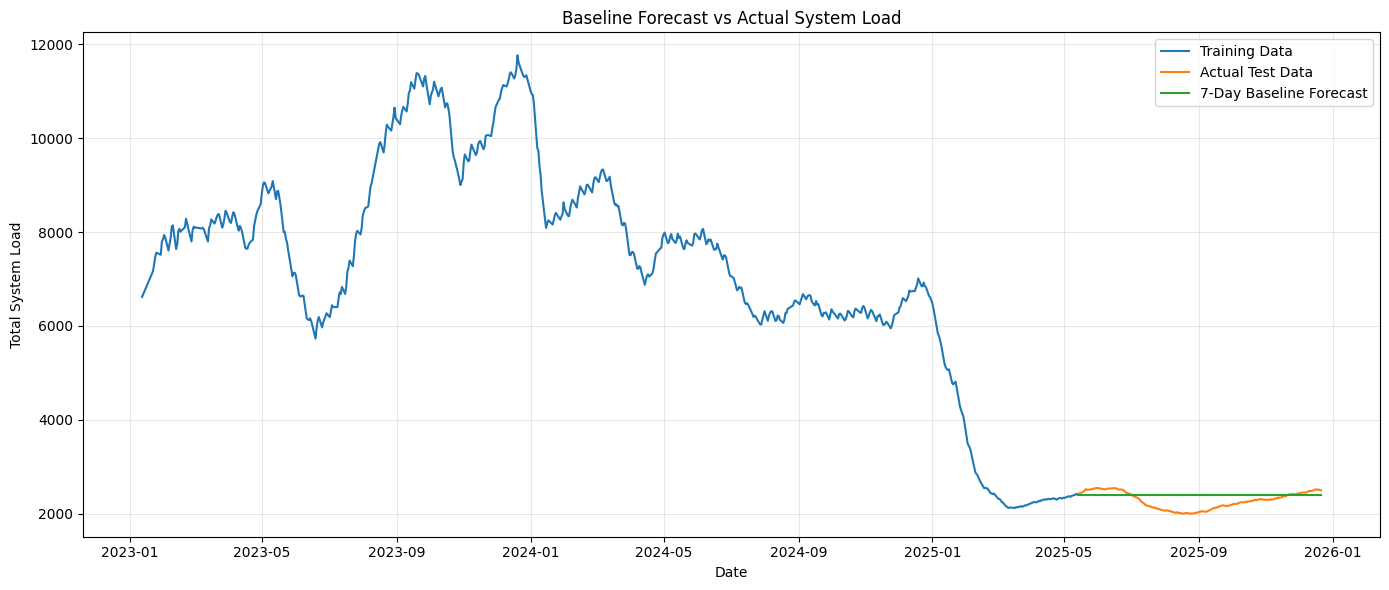

In [32]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train["Total System Load"],
    label="Training Data"
)

plt.plot(
    test.index,
    test["Total System Load"],
    label="Actual Test Data"
)

plt.plot(
    test.index,
    baseline_predictions,
    label="7-Day Baseline Forecast"
)

plt.title("Baseline Forecast vs Actual System Load")
plt.xlabel("Date")
plt.ylabel("Total System Load")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 7F — Now we'll build an actual forecasting model

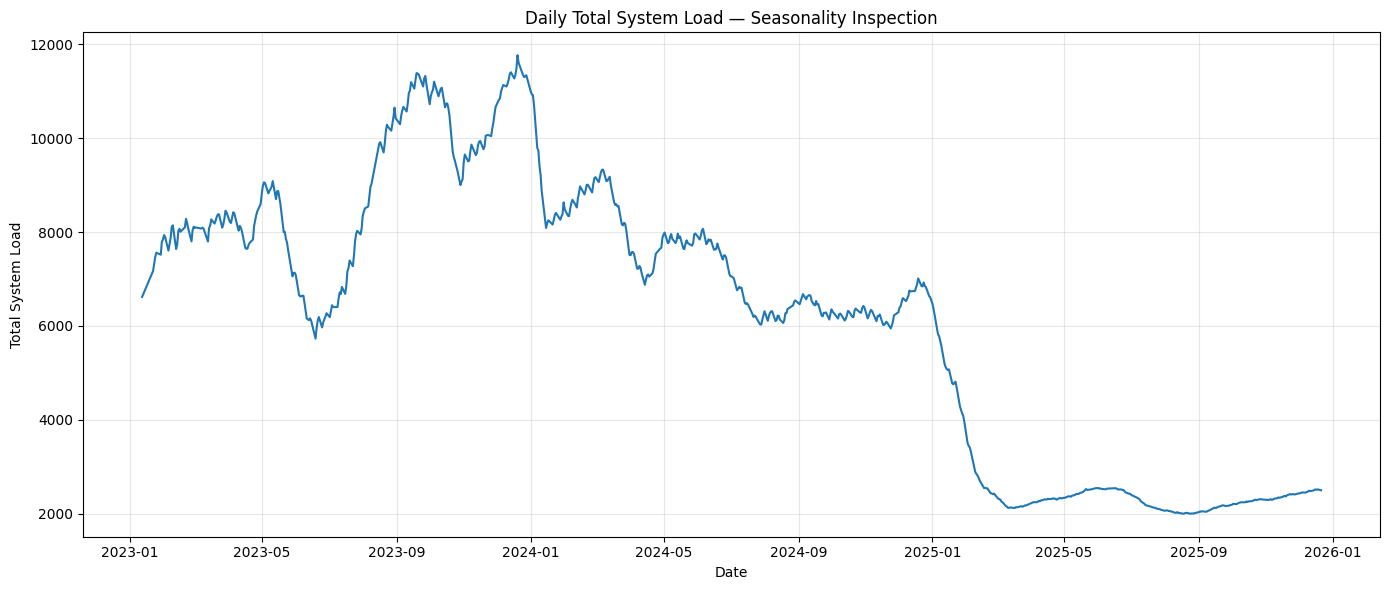

In [33]:
# ============================================
# STEP 7F: WEEKLY SEASONALITY CHECK
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    forecast_df.index,
    forecast_df["Total System Load"]
)

plt.title("Daily Total System Load — Seasonality Inspection")
plt.xlabel("Date")
plt.ylabel("Total System Load")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
# Average load by day of week

weekly_pattern = (
    df_clean
    .assign(
        DayOfWeek=df_clean["Date"].dt.day_name()
    )
    .groupby("DayOfWeek")["Total System Load"]
    .mean()
)

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_pattern = weekly_pattern.reindex(day_order)

display(weekly_pattern)

,Total System Load
DayOfWeek,
Monday,6231.462069
Tuesday,6255.993289
Wednesday,6334.700680
Thursday,6300.000000
Friday,4407.500000
Saturday,NaN
Sunday,6044.407692


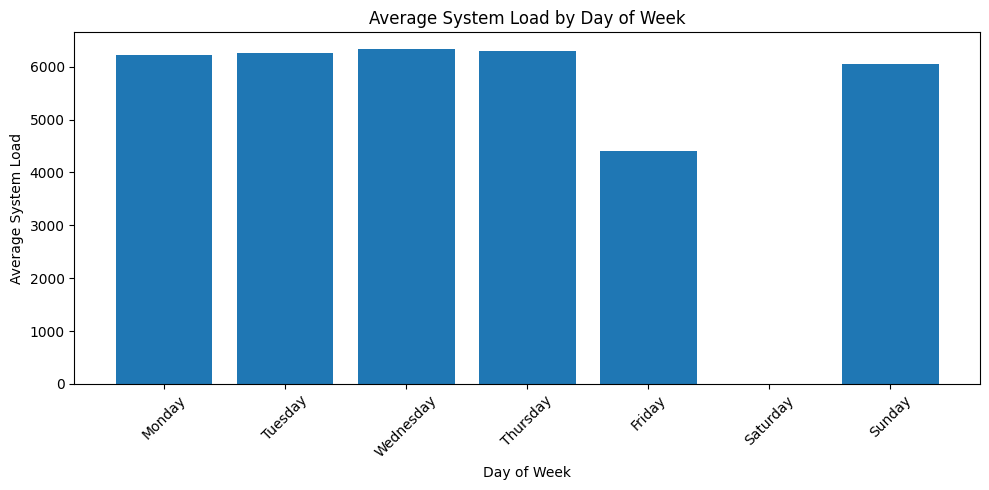

In [35]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekly_pattern.index,
    weekly_pattern.values
)

plt.title("Average System Load by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average System Load")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Step 7G — Fit a SARIMA model

In [38]:
# ============================================
# SARIMA MODEL - FIXED INDEX VERSION
# ============================================

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Use numeric sequential index for SARIMA
train_model = train["Total System Load"].reset_index(drop=True)
test_model = test["Total System Load"].reset_index(drop=True)

# Fit SARIMA
sarima_model = SARIMAX(
    train_model,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)

print("SARIMA model fitted successfully.")
print(sarima_result.summary())

SARIMA model fitted successfully.
                                     SARIMAX Results                                     
Dep. Variable:                 Total System Load   No. Observations:                  576
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -3588.743
Date:                           Fri, 02 Oct 2026   AIC                           7187.486
Time:                                   15:24:54   BIC                           7209.117
Sample:                                        0   HQIC                          7195.933
                                           - 576                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9244      0.026     36.085      0.000       0.874       0.975
ma.L1    

In [39]:
# Forecast test period
sarima_predictions_raw = sarima_result.forecast(
    steps=len(test_model)
)

# Convert predictions to numpy values
sarima_predictions = pd.Series(
    sarima_predictions_raw.values,
    index=test.index
)

display(sarima_predictions.head())

,0
Date,
2025-05-14,2429.558314
2025-05-15,2431.220422
2025-05-18,2430.578418
2025-05-19,2440.423670
2025-05-21,2416.250534


Step 7H — Evaluate the model

In [40]:
# ============================================
# SARIMA EVALUATION
# ============================================

sarima_mae = mean_absolute_error(
    test["Total System Load"],
    sarima_predictions
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test["Total System Load"],
        sarima_predictions
    )
)

comparison = pd.DataFrame({
    "Model": [
        "7-Day Baseline",
        "SARIMA"
    ],
    "MAE": [
        baseline_mae,
        sarima_mae
    ],
    "RMSE": [
        baseline_rmse,
        sarima_rmse
    ]
})

display(comparison)

,Model,MAE,RMSE
0,7-Day Baseline,175.384921,210.164870
1,SARIMA,754.975232,984.928362


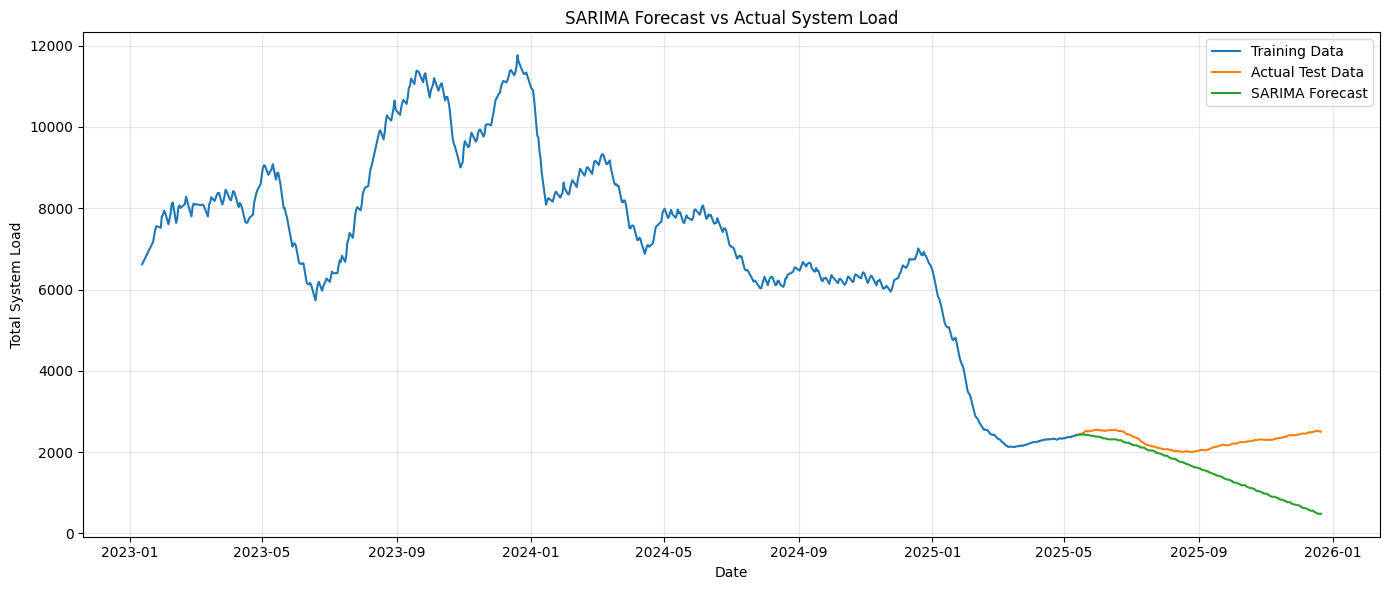

In [41]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train["Total System Load"],
    label="Training Data"
)

plt.plot(
    test.index,
    test["Total System Load"],
    label="Actual Test Data"
)

plt.plot(
    test.index,
    sarima_predictions,
    label="SARIMA Forecast"
)

plt.title("SARIMA Forecast vs Actual System Load")
plt.xlabel("Date")
plt.ylabel("Total System Load")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 7I — Compare the models

In [42]:
# ============================================
# MODEL COMPARISON
# ============================================

display(comparison)

best_model = comparison.loc[
    comparison["MAE"].idxmin(), "Model"
]

print("Model with lower MAE:", best_model)

,Model,MAE,RMSE
0,7-Day Baseline,175.384921,210.164870
1,SARIMA,754.975232,984.928362


Model with lower MAE: 7-Day Baseline


Step 7J — Fit the final SARIMA model

In [43]:
# ============================================
# FINAL SARIMA MODEL
# ============================================

full_series = (
    forecast_df["Total System Load"]
    .reset_index(drop=True)
)

final_model = SARIMAX(
    full_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_result = final_model.fit(disp=False)

print("Final SARIMA model fitted successfully.")

Final SARIMA model fitted successfully.


Step 7K — Generate a 30-observation forecast

In [44]:
# ============================================
# 30-OBSERVATION FUTURE FORECAST
# ============================================

forecast_steps = 30

future_result = final_result.get_forecast(
    steps=forecast_steps
)

future_values = future_result.predicted_mean
future_ci = future_result.conf_int()

print("30 future observations generated.")

display(
    pd.DataFrame({
        "Forecast": future_values,
        "Lower Bound": future_ci.iloc[:, 0],
        "Upper Bound": future_ci.iloc[:, 1]
    }).head(10)
)

30 future observations generated.


,Forecast,Lower Bound,Upper Bound
720,2492.175239,2236.850479,2747.499999
721,2497.072463,2109.341628,2884.803298
722,2473.360519,1967.064971,2979.656068
723,2469.754544,1850.327521,3089.181567
724,2465.958719,1736.183950,3195.733488
725,2457.311431,1618.925663,3295.697198
726,2466.548137,1520.845481,3412.250793
727,2453.652569,1425.059686,3482.245451
728,2457.484114,1347.252873,3567.715355
729,2440.348609,1249.679107,3631.018111


Step 7L — Give the forecast actual dates

In [45]:
# ============================================
# ASSIGN FUTURE DATES
# ============================================

last_date = df_clean["Date"].max()

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=forecast_steps,
    freq="D"
)

future_forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecast": future_values.values,
    "Lower Bound": future_ci.iloc[:, 0].values,
    "Upper Bound": future_ci.iloc[:, 1].values
})

display(future_forecast_df)

,Date,Forecast,Lower Bound,Upper Bound
0,2025-12-22,2492.175239,2236.850479,2747.499999
1,2025-12-23,2497.072463,2109.341628,2884.803298
2,2025-12-24,2473.360519,1967.064971,2979.656068
3,2025-12-25,2469.754544,1850.327521,3089.181567
4,2025-12-26,2465.958719,1736.183950,3195.733488
5,2025-12-27,2457.311431,1618.925663,3295.697198
6,2025-12-28,2466.548137,1520.845481,3412.250793
7,2025-12-29,2453.652569,1425.059686,3482.245451
8,2025-12-30,2457.484114,1347.252873,3567.715355
9,2025-12-31,2440.348609,1249.679107,3631.018111


Step 7M — Plot the final forecast

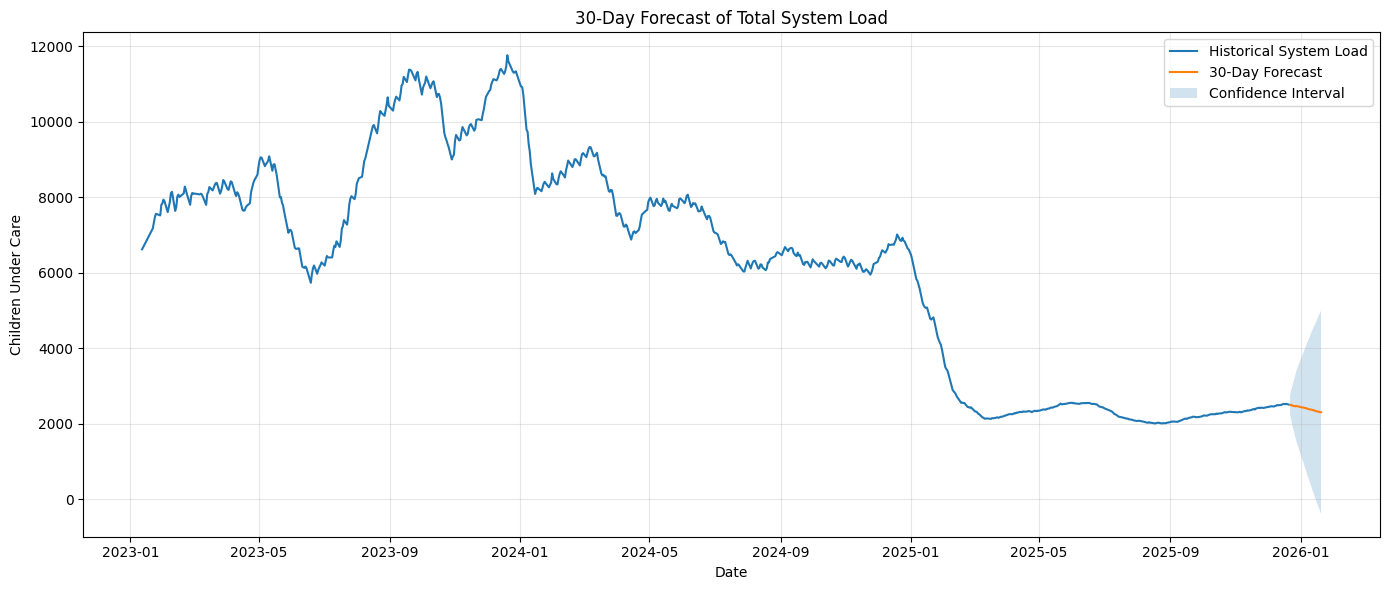

In [46]:
# ============================================
# FINAL FORECAST VISUALIZATION
# ============================================

plt.figure(figsize=(14, 6))

# Historical data
plt.plot(
    df_clean["Date"],
    df_clean["Total System Load"],
    label="Historical System Load"
)

# Forecast
plt.plot(
    future_forecast_df["Date"],
    future_forecast_df["Forecast"],
    label="30-Day Forecast"
)

# Confidence interval
plt.fill_between(
    future_forecast_df["Date"],
    future_forecast_df["Lower Bound"],
    future_forecast_df["Upper Bound"],
    alpha=0.2,
    label="Confidence Interval"
)

plt.title("30-Day Forecast of Total System Load")
plt.xlabel("Date")
plt.ylabel("Children Under Care")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 7N — Summarize the forecast

In [47]:
# ============================================
# FORECAST SUMMARY
# ============================================

forecast_summary = pd.DataFrame({
    "Metric": [
        "Average Forecast Load",
        "Maximum Forecast Load",
        "Minimum Forecast Load",
        "Forecast at End of Period",
        "Average Lower Bound",
        "Average Upper Bound"
    ],
    "Value": [
        future_forecast_df["Forecast"].mean(),
        future_forecast_df["Forecast"].max(),
        future_forecast_df["Forecast"].min(),
        future_forecast_df["Forecast"].iloc[-1],
        future_forecast_df["Lower Bound"].mean(),
        future_forecast_df["Upper Bound"].mean()
    ]
})

display(forecast_summary)

,Metric,Value
0,Average Forecast Load,2401.585193
1,Maximum Forecast Load,2497.072463
2,Minimum Forecast Load,2299.958051
3,Forecast at End of Period,2301.161594
4,Average Lower Bound,815.284860
5,Average Upper Bound,3987.885526


Step 8 — Prepare the final analytical dataset

In [48]:
# ============================================
# STEP 8: FINAL ANALYTICAL DATASET
# ============================================

final_columns = [
    "Date",
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care",
    "Total System Load",
    "Net Intake Pressure",
    "Care Load Growth Rate",
    "7-Day Rolling Load",
    "14-Day Rolling Load",
    "Cumulative Net Intake",
    "Discharge Offset Ratio",
    "High Load",
    "Very High Load",
    "Sustained High Load",
    "Backlog Indicator"
]

final_df = df_clean[final_columns].copy()

print("Final analytical dataset shape:", final_df.shape)

display(final_df.head())

Final analytical dataset shape: (720, 17)


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Total System Load,Net Intake Pressure,Care Load Growth Rate,7-Day Rolling Load,14-Day Rolling Load,Cumulative Net Intake,Discharge Offset Ratio,High Load,Very High Load,Sustained High Load,Backlog Indicator
0,2023-01-12,33.0,53.0,34.0,6566,436.0,6619.0,-402.0,NaN,NaN,NaN,-402.0,12.823529,False,False,False,-402.0
1,2023-01-22,32.0,49.0,39.0,7122,227.0,7171.0,-188.0,8.339628,NaN,NaN,-590.0,5.820513,False,False,False,-590.0
2,2023-01-23,32.0,50.0,39.0,7280,181.0,7330.0,-142.0,2.217264,NaN,NaN,-732.0,4.641026,False,False,False,-732.0
3,2023-01-24,47.0,42.0,47.0,7433,175.0,7475.0,-128.0,1.978172,NaN,NaN,-860.0,3.723404,False,False,False,-860.0
4,2023-01-25,20.0,22.0,41.0,7538,180.0,7560.0,-139.0,1.137124,NaN,NaN,-999.0,4.390244,False,False,False,-999.0


In [51]:
# Save cleaned analytical dataset
final_df.to_csv(
    "UAC_Final_Analytical_Dataset.csv",
    index=False
)

# Save forecast
future_forecast_df.to_csv(
    "UAC_30_Day_Forecast.csv",
    index=False
)

print("Files saved successfully.")

Files saved successfully.


Step 8A — Create the Streamlit project

Create a folder on your computer:

UAC_Care_Load_Analytics


Step 8B — Create requirements.txt

Put this inside requirements.txt:

streamlit,
pandas,
numpy,
plotly,
statsmodels,
scikit-learn.

Step 8C — Create app.py

Step 8D — Run the dashboard

Open Command Prompt/PowerShell in that folder.

Step 9 — Important forecasting correction

In [52]:
seasonal_order=(1, 1, 1, 7)

Step 10 — Build the research findings table

In [53]:
# ============================================
# STEP 10: KEY PROJECT FINDINGS
# ============================================

# Basic system statistics
avg_load = df_clean["Total System Load"].mean()
median_load = df_clean["Total System Load"].median()
max_load = df_clean["Total System Load"].max()
min_load = df_clean["Total System Load"].min()

max_load_row = df_clean.loc[
    df_clean["Total System Load"].idxmax()
]

min_load_row = df_clean.loc[
    df_clean["Total System Load"].idxmin()
]

# Flow statistics
total_transfers = (
    df_clean["Children transferred out of CBP custody"].sum()
)

total_discharges = (
    df_clean["Children discharged from HHS Care"].sum()
)

avg_net_pressure = (
    df_clean["Net Intake Pressure"].mean()
)

positive_pressure_days = (
    df_clean["Net Intake Pressure"] > 0
).sum()

negative_pressure_days = (
    df_clean["Net Intake Pressure"] < 0
).sum()

# Percentiles
p75 = df_clean["Total System Load"].quantile(0.75)
p90 = df_clean["Total System Load"].quantile(0.90)

# Volatility
volatility = (
    df_clean["Total System Load"].std()
    / df_clean["Total System Load"].mean()
)

findings = pd.DataFrame({
    "Metric": [
        "Number of observations",
        "Average system load",
        "Median system load",
        "Minimum system load",
        "Maximum system load",
        "75th percentile",
        "90th percentile",
        "Total transfers",
        "Total discharges",
        "Average net intake pressure",
        "Positive-pressure observations",
        "Negative-pressure observations",
        "Volatility index"
    ],
    "Value": [
        len(df_clean),
        avg_load,
        median_load,
        min_load,
        max_load,
        p75,
        p90,
        total_transfers,
        total_discharges,
        avg_net_pressure,
        positive_pressure_days,
        negative_pressure_days,
        volatility
    ]
})

display(findings)

,Metric,Value
0,Number of observations,720.000000
1,Average system load,6232.769444
2,Median system load,6633.500000
3,Minimum system load,2002.000000
4,Maximum system load,11762.000000
5,75th percentile,8249.500000
6,90th percentile,9920.900000
7,Total transfers,92641.000000
8,Total discharges,124853.000000
9,Average net intake pressure,-44.738889


In [54]:
# ============================================
# LOWEST 10 SYSTEM-LOAD OBSERVATIONS
# ============================================

low_load = (
    df_clean
    .nsmallest(10, "Total System Load")
    [
        [
            "Date",
            "Children in CBP custody",
            "Children in HHS Care",
            "Total System Load",
            "Net Intake Pressure"
        ]
    ]
)

display(low_load)

,Date,Children in CBP custody,Children in HHS Care,Total System Load,Net Intake Pressure
638,2025-08-24,21.0,1981,2002.0,0.0
633,2025-08-17,14.0,1991,2005.0,-1.0
634,2025-08-18,20.0,1985,2005.0,-8.0
641,2025-08-27,19.0,1988,2007.0,-10.0
639,2025-08-25,30.0,1980,2010.0,-3.0
640,2025-08-26,21.0,1989,2010.0,5.0
635,2025-08-19,35.0,1980,2015.0,-8.0
642,2025-08-28,33.0,1984,2017.0,-11.0
631,2025-08-13,22.0,1997,2019.0,-5.0
632,2025-08-14,27.0,1994,2021.0,-7.0


Step 11 — Monthly analysis for the paper

In [55]:
# ============================================
# MONTHLY SYSTEM ANALYSIS
# ============================================

df_clean["Month"] = (
    df_clean["Date"]
    .dt.to_period("M")
)

monthly_analysis = (
    df_clean
    .groupby("Month")
    .agg(
        Observations=("Date", "count"),
        Average_Load=("Total System Load", "mean"),
        Maximum_Load=("Total System Load", "max"),
        Minimum_Load=("Total System Load", "min"),
        Average_Net_Intake=("Net Intake Pressure", "mean"),
        Total_Transfers=(
            "Children transferred out of CBP custody",
            "sum"
        ),
        Total_Discharges=(
            "Children discharged from HHS Care",
            "sum"
        )
    )
    .reset_index()
)

display(monthly_analysis)

,Month,Observations,Average_Load,Maximum_Load,Minimum_Load,Average_Net_Intake,Total_Transfers,Total_Discharges
0,2023-01,8,7413.500000,7839.0,6619.0,-197.500000,276.0,1856.0
1,2023-02,19,7967.105263,8281.0,7604.0,-134.000000,2637.0,5183.0
2,2023-03,19,8190.473684,8453.0,7797.0,-104.000000,3399.0,5375.0
3,2023-04,21,8092.857143,8595.0,7641.0,-81.000000,3967.0,5668.0
4,2023-05,22,8404.090909,9084.0,7056.0,-119.727273,3622.0,6256.0
5,2023-06,20,6282.100000,7084.0,5730.0,-80.650000,2416.0,4029.0
6,2023-07,21,7073.380952,8076.0,6188.0,-24.285714,3897.0,4407.0
7,2023-08,20,9585.100000,10647.0,8349.0,-144.150000,3587.0,6470.0
8,2023-09,19,10992.368421,11382.0,10294.0,-135.526316,3971.0,6546.0
9,2023-10,22,10308.227273,11200.0,9000.0,-254.954545,2049.0,7658.0


In [56]:
# Convert period to string for plotting/export
monthly_analysis["Month"] = (
    monthly_analysis["Month"].astype(str)
)

display(
    monthly_analysis
    .sort_values("Average_Load", ascending=False)
    .head(10)
)

,Month,Observations,Average_Load,Maximum_Load,Minimum_Load,Average_Net_Intake,Total_Transfers,Total_Discharges
11,2023-12,19,11255.263158,11762.0,10814.0,-194.684211,3105.0,6804.0
8,2023-09,19,10992.368421,11382.0,10294.0,-135.526316,3971.0,6546.0
9,2023-10,22,10308.227273,11200.0,9000.0,-254.954545,2049.0,7658.0
10,2023-11,20,9909.600000,10660.0,9485.0,-139.700000,3198.0,5992.0
7,2023-08,20,9585.100000,10647.0,8349.0,-144.150000,3587.0,6470.0
12,2024-01,22,9021.636364,10994.0,8086.0,-165.727273,2850.0,6496.0
13,2024-02,20,8766.800000,9168.0,8338.0,52.950000,6332.0,5273.0
14,2024-03,21,8703.857143,9327.0,7511.0,-22.333333,5209.0,5678.0
4,2023-05,22,8404.090909,9084.0,7056.0,-119.727273,3622.0,6256.0
2,2023-03,19,8190.473684,8453.0,7797.0,-104.000000,3399.0,5375.0


Step 12 — One more metric we should add

In [57]:
# ============================================
# DISCHARGE OFFSET ANALYSIS
# ============================================

total_transfers = (
    df_clean["Children transferred out of CBP custody"]
    .sum()
)

total_discharges = (
    df_clean["Children discharged from HHS Care"]
    .sum()
)

overall_discharge_offset = (
    total_discharges / total_transfers
)

print(
    "Overall Discharge Offset Ratio:",
    round(overall_discharge_offset, 4)
)

print(
    "Percentage:",
    round(overall_discharge_offset * 100, 2),
    "%"
)

Overall Discharge Offset Ratio: 1.3477
Percentage: 134.77 %


Step 13 — Display the Discharge Offset Ratio

In [58]:
# ==========================================
# STEP 13 — DISPLAY DISCHARGE OFFSET RATIO
# ==========================================

print("Total children transferred from CBP to HHS:", int(total_transfers))
print("Total children discharged from HHS:", int(total_discharges))
print(f"Overall Discharge Offset Ratio: {overall_discharge_offset:.2%}")

Total children transferred from CBP to HHS: 92641
Total children discharged from HHS: 124853
Overall Discharge Offset Ratio: 134.77%


Step 14 — Identify the highest and lowest system-load periods

In [59]:
# ==========================================
# STEP 14 — TOP AND LOWEST SYSTEM LOAD DAYS
# ==========================================

top_load_days = (
    df_clean[
        ["Date", "Total System Load",
         "Children in CBP custody",
         "Children in HHS Care"]
    ]
    .sort_values("Total System Load", ascending=False)
    .head(10)
)

lowest_load_days = (
    df_clean[
        ["Date", "Total System Load",
         "Children in CBP custody",
         "Children in HHS Care"]
    ]
    .sort_values("Total System Load", ascending=True)
    .head(10)
)

print("TOP 10 HIGHEST SYSTEM LOAD DAYS")
display(top_load_days)

print("\nLOWEST 10 SYSTEM LOAD DAYS")
display(lowest_load_days)

TOP 10 HIGHEST SYSTEM LOAD DAYS


,Date,Total System Load,Children in CBP custody,Children in HHS Care
224,2023-12-20,11762.0,246.0,11516
225,2023-12-21,11603.0,228.0,11375
223,2023-12-19,11476.0,185.0,11291
220,2023-12-14,11399.0,157.0,11242
161,2023-09-19,11382.0,287.0,11095
162,2023-09-20,11374.0,310.0,11064
219,2023-12-13,11373.0,181.0,11192
163,2023-09-21,11352.0,285.0,11067
226,2023-12-25,11340.0,196.0,11144
222,2023-12-18,11337.0,188.0,11149



LOWEST 10 SYSTEM LOAD DAYS


,Date,Total System Load,Children in CBP custody,Children in HHS Care
638,2025-08-24,2002.0,21.0,1981
633,2025-08-17,2005.0,14.0,1991
634,2025-08-18,2005.0,20.0,1985
641,2025-08-27,2007.0,19.0,1988
639,2025-08-25,2010.0,30.0,1980
640,2025-08-26,2010.0,21.0,1989
635,2025-08-19,2015.0,35.0,1980
642,2025-08-28,2017.0,33.0,1984
631,2025-08-13,2019.0,22.0,1997
637,2025-08-21,2021.0,49.0,1972


Step 15 — Monthly Trend Analysis

In [60]:
# ==========================================
# STEP 15 — MONTHLY TREND ANALYSIS
# ==========================================

# Create month column
df_clean["Month"] = df_clean["Date"].dt.to_period("M")

monthly_analysis = (
    df_clean
    .groupby("Month")
    .agg(
        Observations=("Date", "count"),
        Average_Load=("Total System Load", "mean"),
        Maximum_Load=("Total System Load", "max"),
        Minimum_Load=("Total System Load", "min"),
        Average_Net_Intake=("Net Intake Pressure", "mean"),
        Total_Transfers=("Children transferred out of CBP custody", "sum"),
        Total_Discharges=("Children discharged from HHS Care", "sum")
    )
    .reset_index()
)

# Convert Period to string for easier display/export
monthly_analysis["Month"] = monthly_analysis["Month"].astype(str)

display(monthly_analysis)

,Month,Observations,Average_Load,Maximum_Load,Minimum_Load,Average_Net_Intake,Total_Transfers,Total_Discharges
0,2023-01,8,7413.500000,7839.0,6619.0,-197.500000,276.0,1856.0
1,2023-02,19,7967.105263,8281.0,7604.0,-134.000000,2637.0,5183.0
2,2023-03,19,8190.473684,8453.0,7797.0,-104.000000,3399.0,5375.0
3,2023-04,21,8092.857143,8595.0,7641.0,-81.000000,3967.0,5668.0
4,2023-05,22,8404.090909,9084.0,7056.0,-119.727273,3622.0,6256.0
5,2023-06,20,6282.100000,7084.0,5730.0,-80.650000,2416.0,4029.0
6,2023-07,21,7073.380952,8076.0,6188.0,-24.285714,3897.0,4407.0
7,2023-08,20,9585.100000,10647.0,8349.0,-144.150000,3587.0,6470.0
8,2023-09,19,10992.368421,11382.0,10294.0,-135.526316,3971.0,6546.0
9,2023-10,22,10308.227273,11200.0,9000.0,-254.954545,2049.0,7658.0


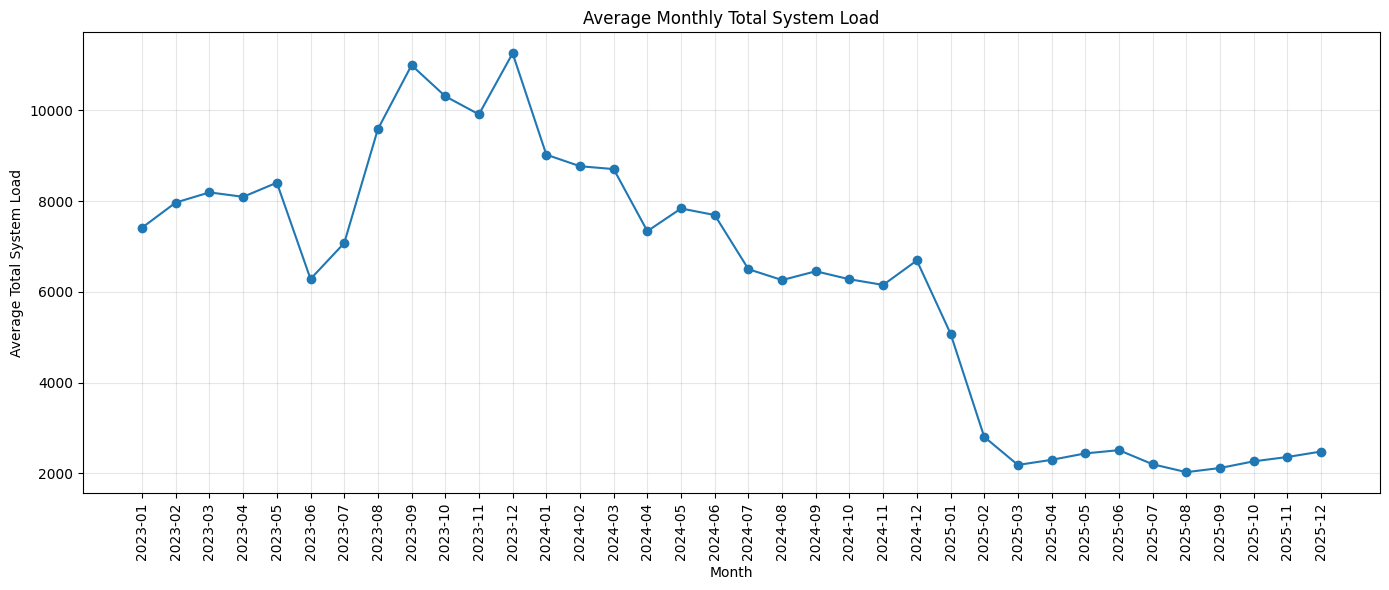

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Average_Load"],
    marker="o"
)

plt.title("Average Monthly Total System Load")
plt.xlabel("Month")
plt.ylabel("Average Total System Load")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 16 — Identify Sustained High-Load Periods

In [62]:
# ==========================================
# STEP 16 — SUSTAINED HIGH-LOAD PERIODS
# ==========================================

# Use the 75th percentile as the high-load threshold
high_load_threshold = df_clean["Total System Load"].quantile(0.75)

# Sort by date
high_load_df = df_clean[
    ["Date", "Total System Load"]
].sort_values("Date").copy()

# Identify high-load days
high_load_df["High_Load"] = (
    high_load_df["Total System Load"] >= high_load_threshold
)

# A new group starts when:
# 1. the previous day was not high-load, OR
# 2. there is a calendar-date gap
date_gap = high_load_df["Date"].diff().dt.days

high_load_df["New_Group"] = (
    (~high_load_df["High_Load"].shift(1, fill_value=False))
    | (date_gap != 1)
)

high_load_df["Group"] = high_load_df["New_Group"].cumsum()

# Keep only high-load observations
high_periods = high_load_df[
    high_load_df["High_Load"]
].copy()

# Summarize continuous high-load periods
sustained_periods = (
    high_periods
    .groupby("Group")
    .agg(
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Days=("Date", "count"),
        Average_Load=("Total System Load", "mean"),
        Maximum_Load=("Total System Load", "max")
    )
    .reset_index(drop=True)
)

# Keep periods lasting at least 3 consecutive calendar days
sustained_periods = sustained_periods[
    sustained_periods["Days"] >= 3
].sort_values(
    "Average_Load",
    ascending=False
)

print(f"High-load threshold (75th percentile): {high_load_threshold:,.2f}")
print(f"\nNumber of sustained high-load periods: {len(sustained_periods)}")

display(sustained_periods)

High-load threshold (75th percentile): 8,249.50

Number of sustained high-load periods: 38


,Start_Date,End_Date,Days,Average_Load,Maximum_Load
30,2023-12-17,2023-12-21,5,11489.200000,11762.0
31,2023-12-25,2023-12-28,4,11321.250000,11340.0
16,2023-09-17,2023-09-21,5,11277.800000,11382.0
29,2023-12-10,2023-12-14,5,11255.400000,11399.0
17,2023-09-24,2023-09-28,5,11198.400000,11321.0
19,2023-10-09,2023-10-12,4,10993.250000,11072.0
28,2023-12-03,2023-12-07,5,10968.400000,11129.0
18,2023-10-01,2023-10-05,5,10963.400000,11200.0
15,2023-09-10,2023-09-14,5,10891.600000,11190.0
32,2024-01-01,2024-01-04,4,10887.500000,10994.0


Step 17 — Rolling Load Analysis

In [63]:
# ==========================================
# STEP 17 — ROLLING LOAD ANALYSIS
# ==========================================

# Calculate rolling averages based on observed records
df_clean["7-Observation Rolling Load"] = (
    df_clean["Total System Load"]
    .rolling(window=7)
    .mean()
)

df_clean["14-Observation Rolling Load"] = (
    df_clean["Total System Load"]
    .rolling(window=14)
    .mean()
)

# Display the latest observations
rolling_analysis = df_clean[
    [
        "Date",
        "Total System Load",
        "7-Observation Rolling Load",
        "14-Observation Rolling Load"
    ]
].tail(20)

display(rolling_analysis)

,Date,Total System Load,7-Observation Rolling Load,14-Observation Rolling Load
700,2025-11-23,2421.0,2379.428571,2348.285714
701,2025-11-24,2411.0,2389.142857,2356.428571
702,2025-11-25,2422.0,2397.714286,2364.928571
703,2025-11-27,2413.0,2402.714286,2372.071429
704,2025-11-30,2433.0,2409.857143,2381.785714
705,2025-12-01,2436.0,2419.000000,2389.571429
706,2025-12-02,2441.0,2425.285714,2397.285714
707,2025-12-03,2451.0,2429.571429,2404.500000
708,2025-12-04,2457.0,2436.142857,2412.642857
709,2025-12-07,2453.0,2440.571429,2419.142857


Step 17A — Plot the rolling trends

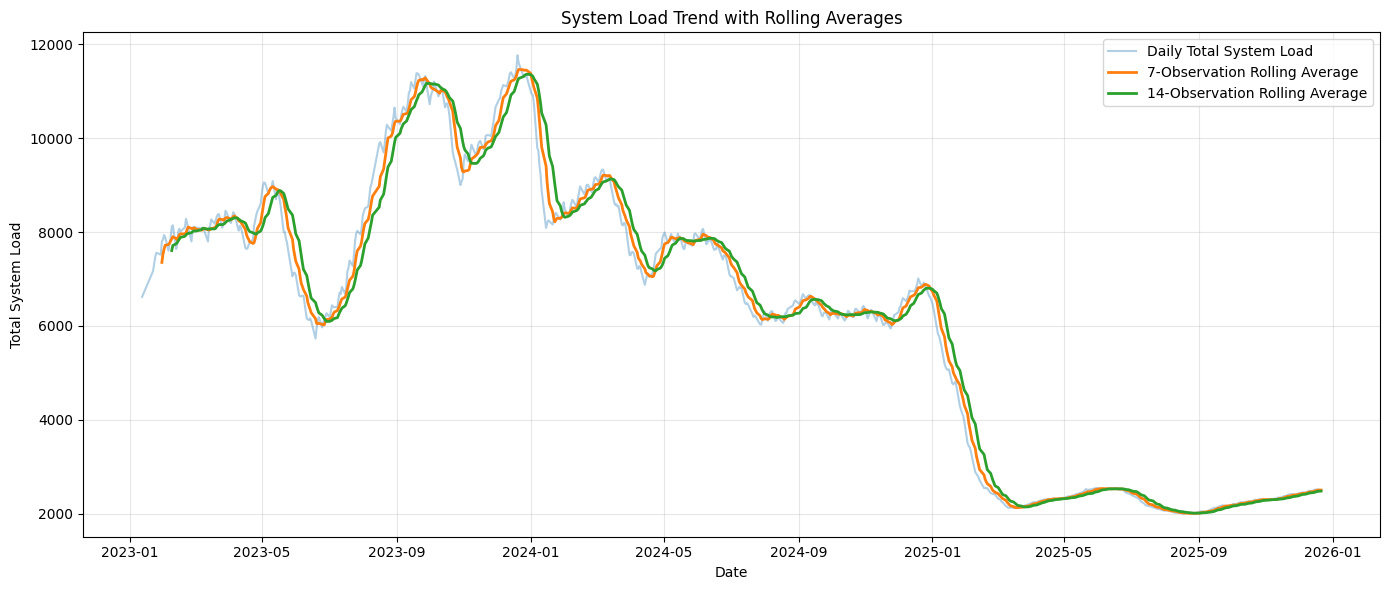

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Total System Load"],
    alpha=0.35,
    label="Daily Total System Load"
)

plt.plot(
    df_clean["Date"],
    df_clean["7-Observation Rolling Load"],
    linewidth=2,
    label="7-Observation Rolling Average"
)

plt.plot(
    df_clean["Date"],
    df_clean["14-Observation Rolling Load"],
    linewidth=2,
    label="14-Observation Rolling Average"
)

plt.title("System Load Trend with Rolling Averages")
plt.xlabel("Date")
plt.ylabel("Total System Load")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 18 — Final KPI Summary

In [65]:
# ==========================================
# STEP 18 — FINAL KPI SUMMARY
# ==========================================

# Core KPIs
total_children_under_care = df_clean["Total System Load"].mean()

avg_net_intake_pressure = df_clean["Net Intake Pressure"].mean()

care_load_volatility = (
    df_clean["Total System Load"].std()
    / df_clean["Total System Load"].mean()
)

backlog_accumulation_rate = (
    df_clean["Net Intake Pressure"] > 0
).mean()

discharge_offset_ratio = (
    df_clean["Children discharged from HHS Care"].sum()
    / df_clean["Children transferred out of CBP custody"].sum()
)

# Additional useful metrics
peak_system_load = df_clean["Total System Load"].max()

minimum_system_load = df_clean["Total System Load"].min()

p75_system_load = df_clean["Total System Load"].quantile(0.75)

p90_system_load = df_clean["Total System Load"].quantile(0.90)

positive_intake_days = (
    df_clean["Net Intake Pressure"] > 0
).sum()

negative_intake_days = (
    df_clean["Net Intake Pressure"] < 0
).sum()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Average Total Children Under Care",
        "Average Net Intake Pressure",
        "Care Load Volatility Index",
        "Backlog Accumulation Rate",
        "Discharge Offset Ratio",
        "Peak System Load",
        "Minimum System Load",
        "75th Percentile System Load",
        "90th Percentile System Load",
        "Positive Net Intake Days",
        "Negative Net Intake Days"
    ],
    "Value": [
        total_children_under_care,
        avg_net_intake_pressure,
        care_load_volatility,
        backlog_accumulation_rate,
        discharge_offset_ratio,
        peak_system_load,
        minimum_system_load,
        p75_system_load,
        p90_system_load,
        positive_intake_days,
        negative_intake_days
    ]
})

display(kpi_summary)

,KPI,Value
0,Average Total Children Under Care,6232.769444
1,Average Net Intake Pressure,-44.738889
2,Care Load Volatility Index,0.468244
3,Backlog Accumulation Rate,0.330556
4,Discharge Offset Ratio,1.347708
5,Peak System Load,11762.000000
6,Minimum System Load,2002.000000
7,75th Percentile System Load,8249.500000
8,90th Percentile System Load,9920.900000
9,Positive Net Intake Days,238.000000


Step 18A — Make the KPI table easier to read

In [66]:
kpi_display = kpi_summary.copy()

kpi_display["Value"] = kpi_display["Value"].round(2)

display(kpi_display)

,KPI,Value
0,Average Total Children Under Care,6232.77
1,Average Net Intake Pressure,-44.74
2,Care Load Volatility Index,0.47
3,Backlog Accumulation Rate,0.33
4,Discharge Offset Ratio,1.35
5,Peak System Load,11762.00
6,Minimum System Load,2002.00
7,75th Percentile System Load,8249.50
8,90th Percentile System Load,9920.90
9,Positive Net Intake Days,238.00


Step 19 — Prepare the Forecasting Dataset

In [67]:
# ==========================================
# STEP 19 — PREPARE FORECASTING DATA
# ==========================================

# Make a separate forecasting dataset
forecast_df = df_clean[
    ["Date", "Total System Load"]
].copy()

# Sort chronologically
forecast_df = forecast_df.sort_values("Date").reset_index(drop=True)

# Remove any missing target values
forecast_df = forecast_df.dropna(
    subset=["Total System Load"]
).reset_index(drop=True)

print("Forecasting observations:", len(forecast_df))
print("Start date:", forecast_df["Date"].min().date())
print("End date:", forecast_df["Date"].max().date())

display(forecast_df.head())
display(forecast_df.tail())

Forecasting observations: 720
Start date: 2023-01-12
End date: 2025-12-21


,Date,Total System Load
0,2023-01-12,6619.0
1,2023-01-22,7171.0
2,2023-01-23,7330.0
3,2023-01-24,7475.0
4,2023-01-25,7560.0


,Date,Total System Load
715,2025-12-15,2512.0
716,2025-12-16,2522.0
717,2025-12-17,2512.0
718,2025-12-18,2522.0
719,2025-12-21,2502.0


Step 19A — Chronological train/test split

In [68]:
# ==========================================
# STEP 19B — TRAIN / TEST SPLIT
# ==========================================

split_index = int(len(forecast_df) * 0.80)

train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train["Date"].min().date(), "to", train["Date"].max().date())

print("\nTesting period:")
print(test["Date"].min().date(), "to", test["Date"].max().date())

Training observations: 576
Testing observations: 144

Training period:
2023-01-12 to 2025-05-13

Testing period:
2025-05-14 to 2025-12-21


Step 19B — Plot the split

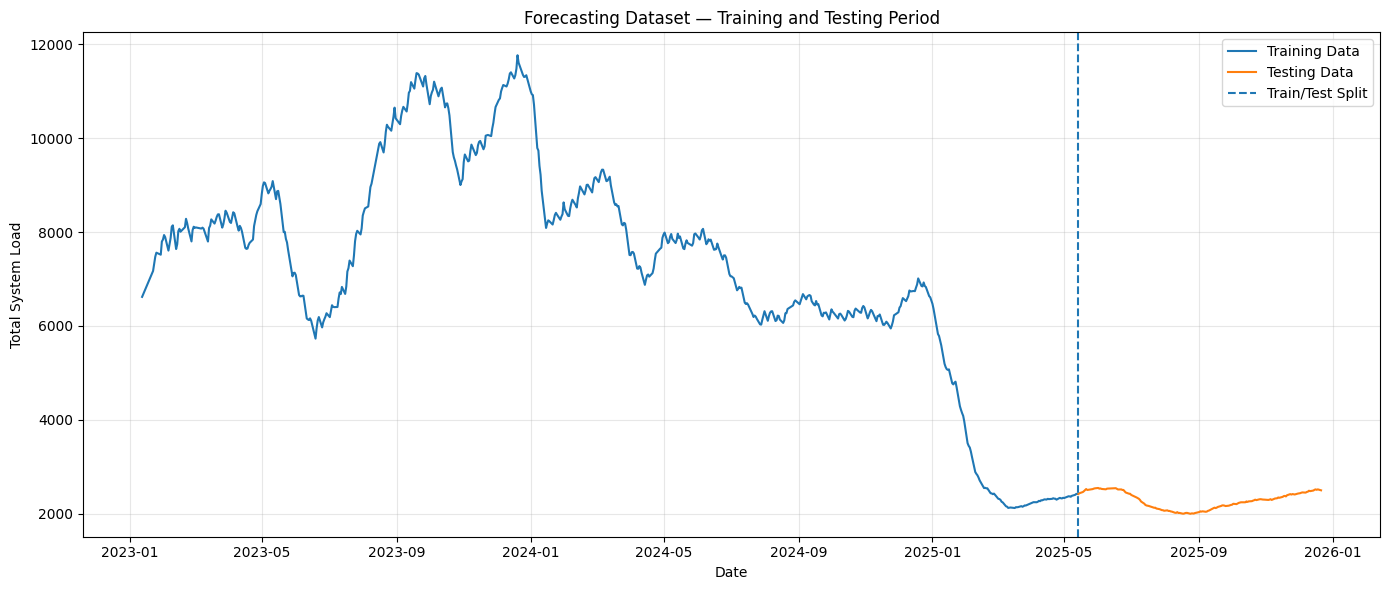

In [69]:
plt.figure(figsize=(14, 6))

plt.plot(
    train["Date"],
    train["Total System Load"],
    label="Training Data"
)

plt.plot(
    test["Date"],
    test["Total System Load"],
    label="Testing Data"
)

plt.axvline(
    test["Date"].min(),
    linestyle="--",
    label="Train/Test Split"
)

plt.title("Forecasting Dataset — Training and Testing Period")
plt.xlabel("Date")
plt.ylabel("Total System Load")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 20 — Create the Baseline Forecast

In [70]:
# ==========================================
# STEP 20 — 7-OBSERVATION BASELINE FORECAST
# ==========================================

# Use the last 7 training observations
last_7_values = train["Total System Load"].tail(7)

# Baseline forecast = average of last 7 observations
baseline_value = last_7_values.mean()

# Forecast the entire test period with the same baseline value
baseline_predictions = pd.Series(
    baseline_value,
    index=test.index
)

print(f"Baseline forecast value: {baseline_value:,.2f}")
print(f"Test observations: {len(test)}")

Baseline forecast value: 2,392.86
Test observations: 144


Step 20A — Evaluate the baseline

In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_mae = mean_absolute_error(
    test["Total System Load"],
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        test["Total System Load"],
        baseline_predictions
    )
)

print(f"Baseline MAE:  {baseline_mae:,.2f}")
print(f"Baseline RMSE: {baseline_rmse:,.2f}")

Baseline MAE:  175.38
Baseline RMSE: 210.16


Step 20B — Plot baseline vs actual

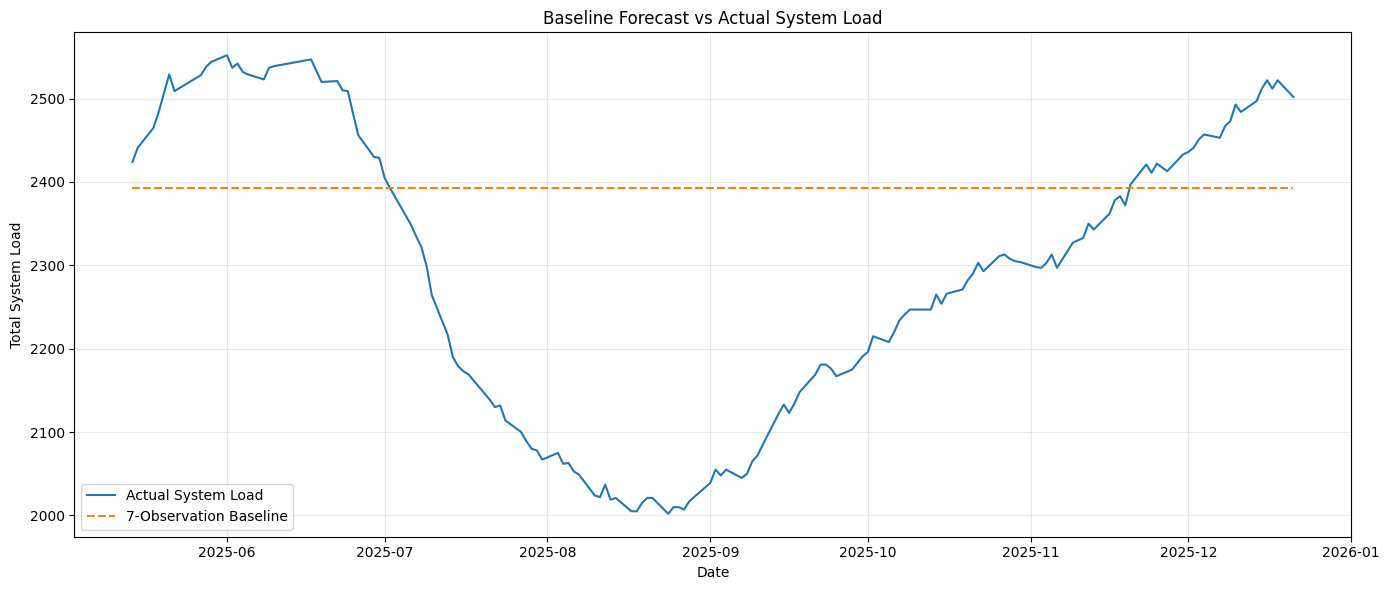

In [72]:
plt.figure(figsize=(14, 6))

plt.plot(
    test["Date"],
    test["Total System Load"],
    label="Actual System Load"
)

plt.plot(
    test["Date"],
    baseline_predictions,
    linestyle="--",
    label="7-Observation Baseline"
)

plt.title("Baseline Forecast vs Actual System Load")
plt.xlabel("Date")
plt.ylabel("Total System Load")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 21 — Fit the ARIMA Forecasting Model

In [73]:
# ==========================================
# STEP 21 — ARIMA MODEL
# ==========================================

from statsmodels.tsa.arima.model import ARIMA

# Use the observed training sequence
train_model = train["Total System Load"].reset_index(drop=True)
test_model = test["Total System Load"].reset_index(drop=True)

# Fit ARIMA(1,1,1)
arima_model = ARIMA(
    train_model,
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

# Forecast the test period
arima_predictions_raw = arima_result.forecast(
    steps=len(test_model)
)

arima_predictions = pd.Series(
    arima_predictions_raw.values,
    index=test.index
)

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:      Total System Load   No. Observations:                  576
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -3710.850
Date:                Fri, 02 Oct 2026   AIC                           7427.699
Time:                        17:57:35   BIC                           7440.762
Sample:                             0   HQIC                          7432.794
                                - 576                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0164      0.223      0.074      0.941      -0.421       0.454
ma.L1          0.1852      0.221      0.838      0.402      -0.248       0.618
sigma2      2.366e+04    846.125     27.963      0.0

Step 21A — Evaluate ARIMA

In [74]:
# ==========================================
# STEP 21A — ARIMA EVALUATION
# ==========================================

arima_mae = mean_absolute_error(
    test["Total System Load"],
    arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test["Total System Load"],
        arima_predictions
    )
)

print(f"ARIMA MAE:  {arima_mae:,.2f}")
print(f"ARIMA RMSE: {arima_rmse:,.2f}")

ARIMA MAE:  185.95
ARIMA RMSE: 227.25


Step 21B — Compare baseline and ARIMA

In [75]:
# ==========================================
# STEP 21B — MODEL COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "7-Observation Baseline",
        "ARIMA(1,1,1)"
    ],
    "MAE": [
        baseline_mae,
        arima_mae
    ],
    "RMSE": [
        baseline_rmse,
        arima_rmse
    ]
})

display(comparison)

,Model,MAE,RMSE
0,7-Observation Baseline,175.384921,210.164870
1,"ARIMA(1,1,1)",185.949452,227.252266


Step 21C — Plot ARIMA against actual values

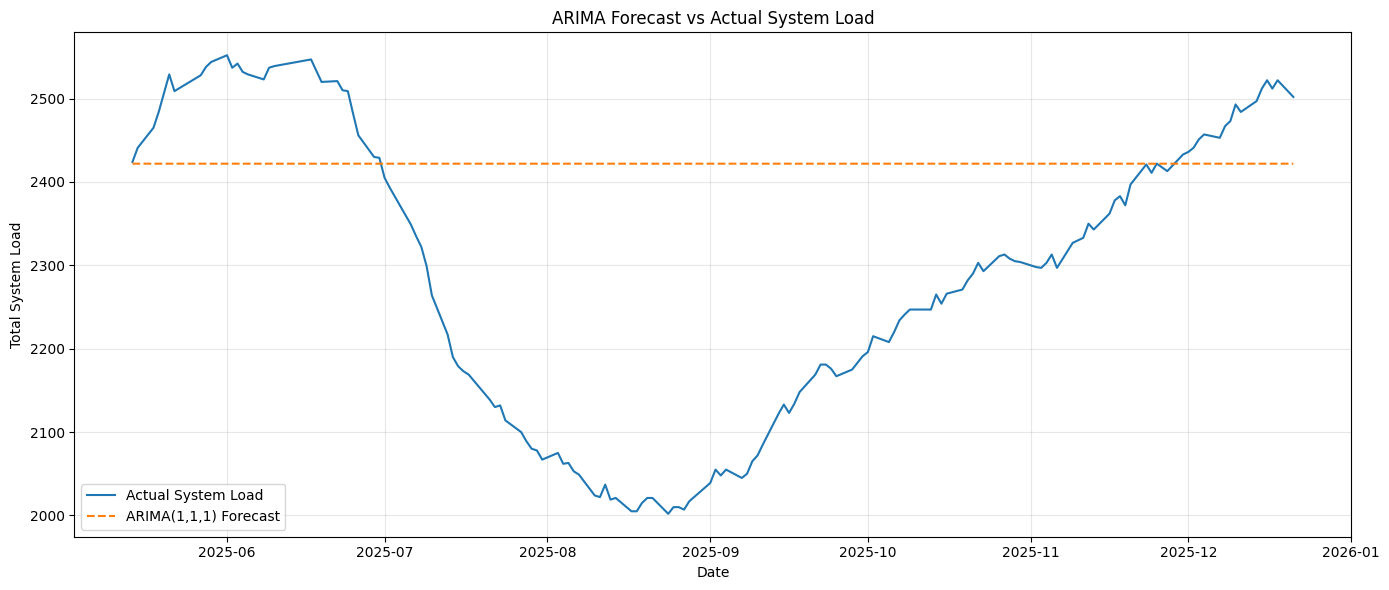

In [76]:
# ==========================================
# STEP 21C — ARIMA FORECAST PLOT
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    test["Date"],
    test["Total System Load"],
    label="Actual System Load"
)

plt.plot(
    test["Date"],
    arima_predictions,
    linestyle="--",
    label="ARIMA(1,1,1) Forecast"
)

plt.title("ARIMA Forecast vs Actual System Load")
plt.xlabel("Date")
plt.ylabel("Total System Load")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 22 — Compare Forecast Accuracy

In [77]:
# ==========================================
# STEP 22 — FORECAST PERFORMANCE COMPARISON
# ==========================================

comparison["MAE Improvement (%)"] = (
    (baseline_mae - comparison["MAE"]) / baseline_mae
) * 100

comparison["RMSE Improvement (%)"] = (
    (baseline_rmse - comparison["RMSE"]) / baseline_rmse
) * 100

display(comparison.round(2))

,Model,MAE,RMSE,MAE Improvement (%),RMSE Improvement (%)
0,7-Observation Baseline,175.38,210.16,0.00,0.00
1,"ARIMA(1,1,1)",185.95,227.25,-6.02,-8.13


Step 22A — Print the results clearly

In [78]:
print("BASELINE MAE :", round(baseline_mae, 2))
print("ARIMA MAE    :", round(arima_mae, 2))

print()

print("BASELINE RMSE:", round(baseline_rmse, 2))
print("ARIMA RMSE   :", round(arima_rmse, 2))

print()

if arima_mae < baseline_mae:
    print("ARIMA has lower MAE than the baseline.")
else:
    print("ARIMA does not have lower MAE than the baseline.")

if arima_rmse < baseline_rmse:
    print("ARIMA has lower RMSE than the baseline.")
else:
    print("ARIMA does not have lower RMSE than the baseline.")

BASELINE MAE : 175.38
ARIMA MAE    : 185.95

BASELINE RMSE: 210.16
ARIMA RMSE   : 227.25

ARIMA does not have lower MAE than the baseline.
ARIMA does not have lower RMSE than the baseline.


Step 23 — Select the Forecasting Model

In [79]:
# ==========================================
# STEP 23 — MODEL SELECTION
# ==========================================

# Find the model with the lowest MAE
best_mae_model = comparison.loc[
    comparison["MAE"].idxmin(), "Model"
]

# Find the model with the lowest RMSE
best_rmse_model = comparison.loc[
    comparison["RMSE"].idxmin(), "Model"
]

print("Model with lowest MAE :", best_mae_model)
print("Model with lowest RMSE:", best_rmse_model)

print("\nModel comparison:")
display(comparison.round(2))

Model with lowest MAE : 7-Observation Baseline
Model with lowest RMSE: 7-Observation Baseline

Model comparison:


,Model,MAE,RMSE,MAE Improvement (%),RMSE Improvement (%)
0,7-Observation Baseline,175.38,210.16,0.00,0.00
1,"ARIMA(1,1,1)",185.95,227.25,-6.02,-8.13


Step 23A — Calculate the ARIMA improvement

In [80]:
# ==========================================
# STEP 23A — ARIMA IMPROVEMENT
# ==========================================

mae_improvement = (
    (baseline_mae - arima_mae)
    / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - arima_rmse)
    / baseline_rmse
) * 100

print(f"ARIMA MAE change relative to baseline: {mae_improvement:.2f}%")
print(f"ARIMA RMSE change relative to baseline: {rmse_improvement:.2f}%")

ARIMA MAE change relative to baseline: -6.02%
ARIMA RMSE change relative to baseline: -8.13%


Step 24 — Generate the Final Future Forecast

In [81]:
# ==========================================
# STEP 24 — FINAL 30-OBSERVATION FORECAST
# ==========================================

# Use all available observed system-load values
full_model_data = forecast_df["Total System Load"].reset_index(drop=True)

# Fit final ARIMA model
final_arima = ARIMA(
    full_model_data,
    order=(1, 1, 1)
)

final_arima_result = final_arima.fit()

# Forecast next 30 observations
forecast_steps = 30

future_forecast = final_arima_result.forecast(
    steps=forecast_steps
)

# Create future dates after the last observed date
last_observed_date = forecast_df["Date"].max()

future_dates = pd.date_range(
    start=last_observed_date + pd.Timedelta(days=1),
    periods=forecast_steps,
    freq="D"
)

# Create forecast dataframe
forecast_output = pd.DataFrame({
    "Date": future_dates,
    "Forecasted Total System Load": future_forecast.values
})

display(forecast_output)

,Date,Forecasted Total System Load
0,2025-12-22,2497.541462
1,2025-12-23,2497.461957
2,2025-12-24,2497.460539
3,2025-12-25,2497.460514
4,2025-12-26,2497.460513
5,2025-12-27,2497.460513
6,2025-12-28,2497.460513
7,2025-12-29,2497.460513
8,2025-12-30,2497.460513
9,2025-12-31,2497.460513


Step 24A — Plot the historical data and forecast

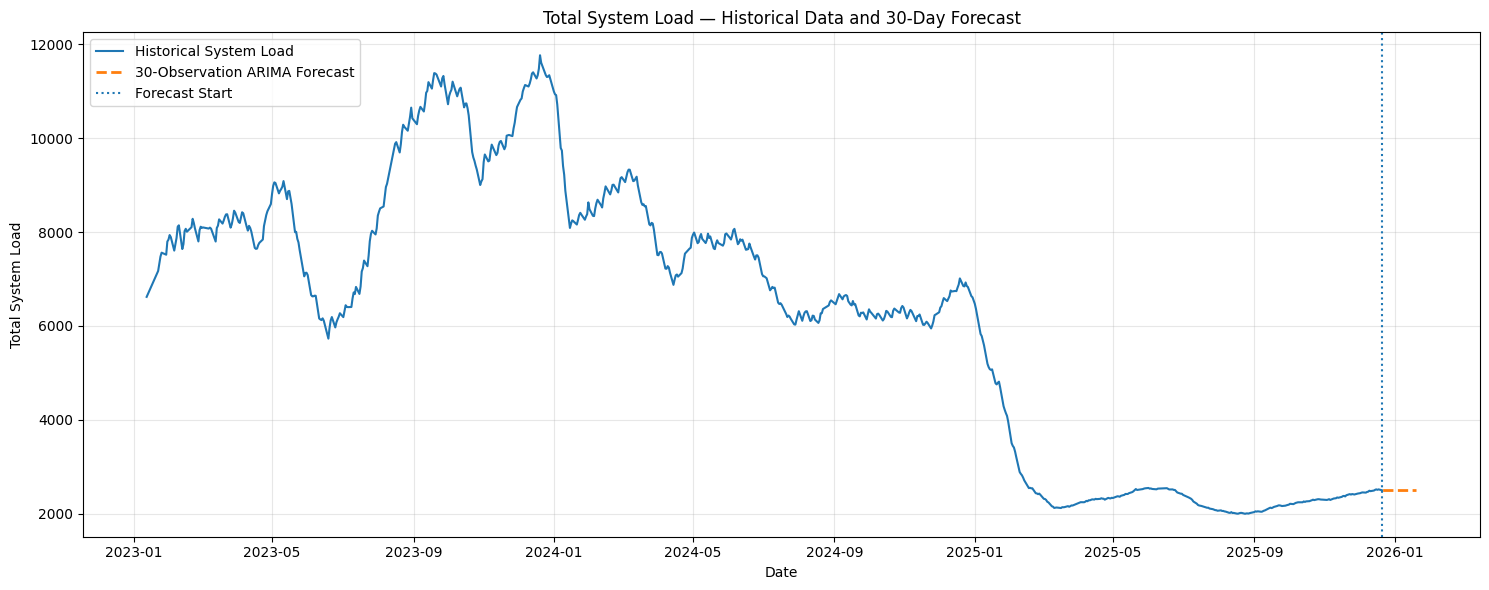

In [82]:
# ==========================================
# STEP 24A — FINAL FORECAST VISUALIZATION
# ==========================================

plt.figure(figsize=(15, 6))

# Historical observations
plt.plot(
    forecast_df["Date"],
    forecast_df["Total System Load"],
    label="Historical System Load"
)

# Future forecast
plt.plot(
    forecast_output["Date"],
    forecast_output["Forecasted Total System Load"],
    linestyle="--",
    linewidth=2,
    label="30-Observation ARIMA Forecast"
)

# Forecast boundary
plt.axvline(
    last_observed_date,
    linestyle=":",
    label="Forecast Start"
)

plt.title("Total System Load — Historical Data and 30-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Total System Load")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 24B — Save the forecast

In [83]:
# ==========================================
# STEP 24B — SAVE FORECAST OUTPUT
# ==========================================

forecast_output.to_csv(
    "UAC_30_Day_System_Load_Forecast.csv",
    index=False
)

print("Forecast saved successfully.")

Forecast saved successfully.


Step 25 — Create the Final Research Charts

Step 25A — Total System Load Trend

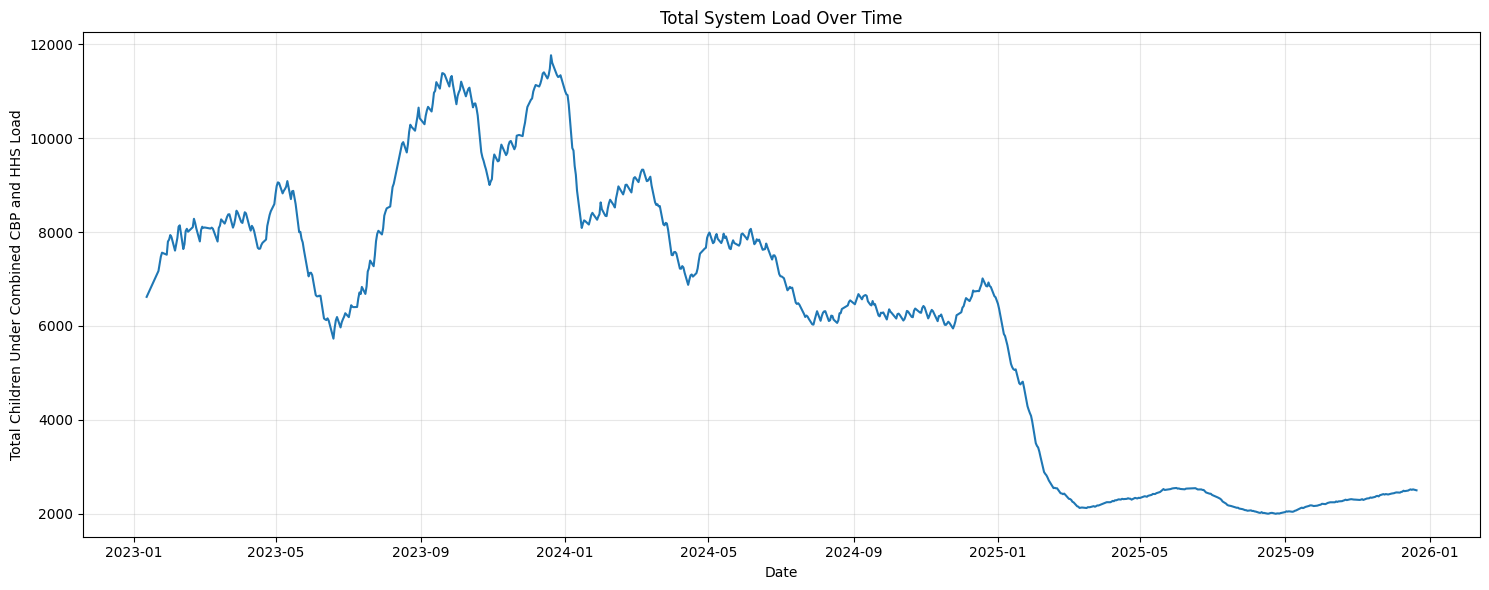

In [84]:
# ==========================================
# STEP 25A — TOTAL SYSTEM LOAD TREND
# ==========================================

plt.figure(figsize=(15, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Total System Load"],
    linewidth=1.5
)

plt.title("Total System Load Over Time")
plt.xlabel("Date")
plt.ylabel("Total Children Under Combined CBP and HHS Load")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 25B — CBP vs HHS Care Load

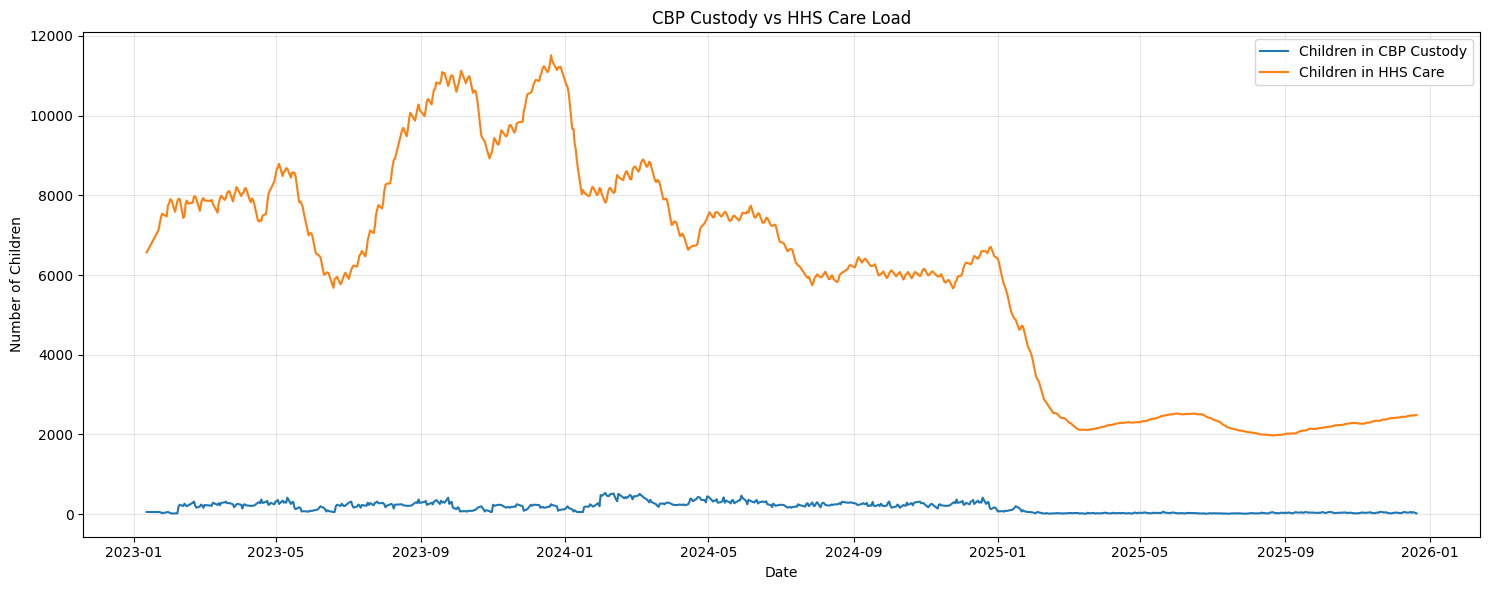

In [85]:
# ==========================================
# STEP 25B — CBP VS HHS LOAD
# ==========================================

plt.figure(figsize=(15, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children in CBP custody"],
    label="Children in CBP Custody"
)

plt.plot(
    df_clean["Date"],
    df_clean["Children in HHS Care"],
    label="Children in HHS Care"
)

plt.title("CBP Custody vs HHS Care Load")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 25C — Transfers vs Discharges

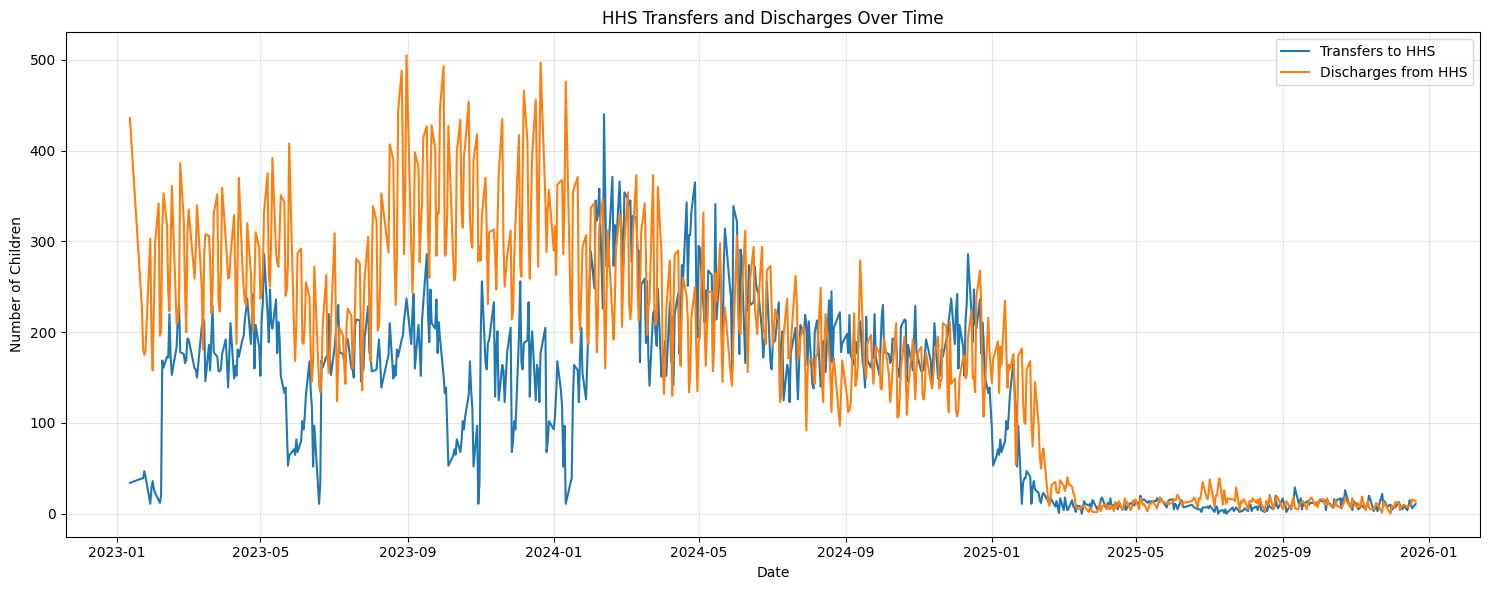

In [86]:
# ==========================================
# STEP 25C — TRANSFERS VS DISCHARGES
# ==========================================

plt.figure(figsize=(15, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Children transferred out of CBP custody"],
    label="Transfers to HHS"
)

plt.plot(
    df_clean["Date"],
    df_clean["Children discharged from HHS Care"],
    label="Discharges from HHS"
)

plt.title("HHS Transfers and Discharges Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 25D — Net Intake Pressure

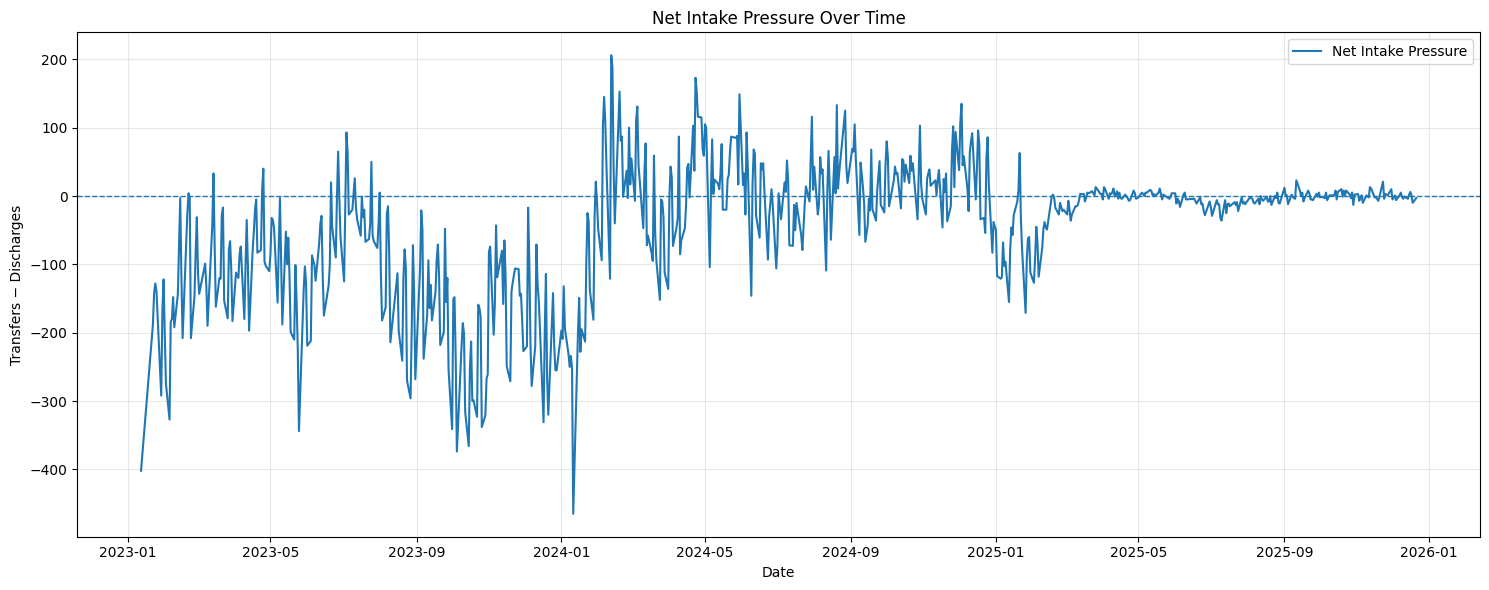

In [87]:
# ==========================================
# STEP 25D — NET INTAKE PRESSURE
# ==========================================

plt.figure(figsize=(15, 6))

plt.plot(
    df_clean["Date"],
    df_clean["Net Intake Pressure"],
    label="Net Intake Pressure"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title("Net Intake Pressure Over Time")
plt.xlabel("Date")
plt.ylabel("Transfers − Discharges")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 26 — Create the Final Results Summary

In [88]:
# ==========================================
# STEP 26 — FINAL RESULTS SUMMARY
# ==========================================

results_summary = pd.DataFrame({
    "Metric": [
        "Analysis Start Date",
        "Analysis End Date",
        "Observed Records",
        "Average Total System Load",
        "Minimum Total System Load",
        "Maximum Total System Load",
        "75th Percentile System Load",
        "90th Percentile System Load",
        "Average Net Intake Pressure",
        "Positive Net Intake Days",
        "Negative Net Intake Days",
        "Care Load Volatility Index",
        "Backlog Accumulation Rate",
        "Discharge Offset Ratio",
        "Peak Load Date",
        "Forecast Horizon"
    ],
    "Value": [
        df_clean["Date"].min().date(),
        df_clean["Date"].max().date(),
        len(df_clean),
        round(df_clean["Total System Load"].mean(), 2),
        round(df_clean["Total System Load"].min(), 2),
        round(df_clean["Total System Load"].max(), 2),
        round(df_clean["Total System Load"].quantile(0.75), 2),
        round(df_clean["Total System Load"].quantile(0.90), 2),
        round(df_clean["Net Intake Pressure"].mean(), 2),
        int((df_clean["Net Intake Pressure"] > 0).sum()),
        int((df_clean["Net Intake Pressure"] < 0).sum()),
        round(care_load_volatility, 4),
        round(backlog_accumulation_rate * 100, 2),
        round(discharge_offset_ratio * 100, 2),
        df_clean.loc[
            df_clean["Total System Load"].idxmax(),
            "Date"
        ].date(),
        "30 observations"
    ]
})

display(results_summary)

,Metric,Value
0,Analysis Start Date,2023-01-12
1,Analysis End Date,2025-12-21
2,Observed Records,720
3,Average Total System Load,6232.77
4,Minimum Total System Load,2002.0
5,Maximum Total System Load,11762.0
6,75th Percentile System Load,8249.5
7,90th Percentile System Load,9920.9
8,Average Net Intake Pressure,-44.74
9,Positive Net Intake Days,238


Step 26A — Save the results

In [89]:
# Save results for later use in the research paper/dashboard

results_summary.to_csv(
    "UAC_Final_Results_Summary.csv",
    index=False
)

monthly_analysis.to_csv(
    "UAC_Monthly_Analysis.csv",
    index=False
)

sustained_periods.to_csv(
    "UAC_Sustained_High_Load_Periods.csv",
    index=False
)

print("Final analysis tables saved successfully.")

Final analysis tables saved successfully.


STEP 27 — Data Quality & Validation Summary

In [90]:
# STEP 27 — DATA QUALITY & VALIDATION SUMMARY

# Make sure dates are correctly formatted and sorted
df_clean["Date"] = pd.to_datetime(df_clean["Date"])
df_clean = df_clean.sort_values("Date").reset_index(drop=True)

# --------------------------------------------------
# 1. Reporting period
# --------------------------------------------------
start_date = df_clean["Date"].min()
end_date = df_clean["Date"].max()

expected_days = (end_date - start_date).days + 1
observed_days = df_clean["Date"].nunique()

# --------------------------------------------------
# 2. Missing calendar dates
# --------------------------------------------------
missing_calendar_days = expected_days - observed_days

# --------------------------------------------------
# 3. Duplicate dates
# --------------------------------------------------
duplicate_dates = df_clean["Date"].duplicated().sum()

# --------------------------------------------------
# 4. Missing values in observed records
# --------------------------------------------------
check_columns = [
    "Children apprehended and placed in CBP custody*",
    "Children in CBP custody",
    "Children transferred out of CBP custody",
    "Children in HHS Care",
    "Children discharged from HHS Care",
    "Total System Load",
    "Net Intake Pressure"
]

# Only use columns that actually exist
check_columns = [c for c in check_columns if c in df_clean.columns]

missing_values = df_clean[check_columns].isna().sum().sum()

# --------------------------------------------------
# 5. Transfer validation
# Transfers should not exceed CBP custody
# --------------------------------------------------
transfer_violations = (
    df_clean["Children transferred out of CBP custody"]
    > df_clean["Children in CBP custody"]
).sum()

# --------------------------------------------------
# 6. Discharge validation
# Discharges should not exceed HHS care
# --------------------------------------------------
discharge_violations = (
    df_clean["Children discharged from HHS Care"]
    > df_clean["Children in HHS Care"]
).sum()

# --------------------------------------------------
# 7. Reporting coverage
# --------------------------------------------------
reporting_coverage = (observed_days / expected_days) * 100

# --------------------------------------------------
# Final summary table
# --------------------------------------------------
data_quality_summary = pd.DataFrame({
    "Metric": [
        "Start Date",
        "End Date",
        "Expected Calendar Days",
        "Observed Dates",
        "Missing Calendar Dates",
        "Duplicate Dates",
        "Missing Values in Observed Records",
        "Transfers > CBP Custody",
        "Discharges > HHS Care",
        "Reporting Coverage (%)"
    ],
    "Value": [
        start_date.date(),
        end_date.date(),
        expected_days,
        observed_days,
        missing_calendar_days,
        duplicate_dates,
        missing_values,
        transfer_violations,
        discharge_violations,
        round(reporting_coverage, 2)
    ]
})

display(data_quality_summary)

,Metric,Value
0,Start Date,2023-01-12
1,End Date,2025-12-21
2,Expected Calendar Days,1075
3,Observed Dates,720
4,Missing Calendar Dates,355
5,Duplicate Dates,0
6,Missing Values in Observed Records,0
7,Transfers > CBP Custody,86
8,Discharges > HHS Care,0
9,Reporting Coverage (%),66.98


STEP 27A — Create a complete daily index

In [91]:
# STEP 27A — COMPLETE DAILY TIME-SERIES INDEX

complete_dates = pd.date_range(
    start=df_clean["Date"].min(),
    end=df_clean["Date"].max(),
    freq="D"
)

daily_df = (
    df_clean
    .set_index("Date")
    .reindex(complete_dates)
    .rename_axis("Date")
    .reset_index()
)

# Flag whether data was actually reported for that date
daily_df["Reporting Available"] = daily_df["Total System Load"].notna()

print("Complete daily index created.")
print("Total calendar days:", len(daily_df))
print("Reported days:", daily_df["Reporting Available"].sum())
print("Missing reporting days:", (~daily_df["Reporting Available"]).sum())

display(daily_df.head())

Complete daily index created.
Total calendar days: 1075
Reported days: 720
Missing reporting days: 355


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Total System Load,Net Intake Pressure,Care Load Growth Rate,7-Day Rolling Load,...,Cumulative Net Intake,Discharge Offset Ratio,Month,High Load,Very High Load,Sustained High Load,Backlog Indicator,7-Observation Rolling Load,14-Observation Rolling Load,Reporting Available
0,2023-01-12,33.0,53.0,34.0,6566.0,436.0,6619.0,-402.0,NaN,NaN,...,-402.0,12.823529,2023-01,False,False,False,-402.0,NaN,NaN,True
1,2023-01-13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,False
2,2023-01-14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,False
3,2023-01-15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,False
4,2023-01-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,False


STEP 27B — Visualize reporting coverage

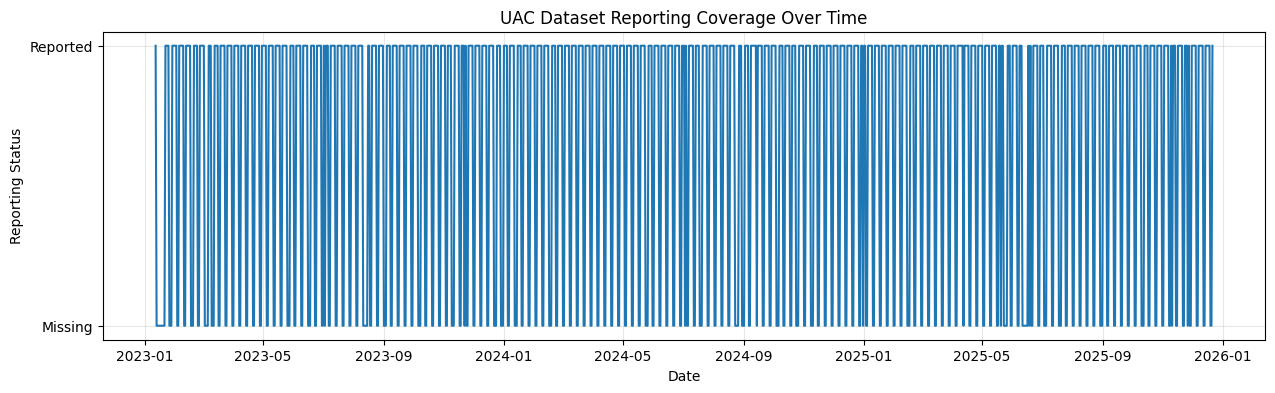

In [92]:
# STEP 27B — REPORTING COVERAGE VISUALIZATION

plt.figure(figsize=(15, 4))

plt.plot(
    daily_df["Date"],
    daily_df["Reporting Available"].astype(int)
)

plt.yticks([0, 1], ["Missing", "Reported"])
plt.xlabel("Date")
plt.ylabel("Reporting Status")
plt.title("UAC Dataset Reporting Coverage Over Time")
plt.grid(True, alpha=0.3)

plt.show()

STEP 28 — Final Forecast Validation

In [93]:
# STEP 28 — FORECAST MODEL VALIDATION

print("MODEL PERFORMANCE COMPARISON")
display(comparison)

# Determine the model with lower error
best_mae_model = comparison.loc[
    comparison["MAE"].idxmin(), "Model"
]

best_rmse_model = comparison.loc[
    comparison["RMSE"].idxmin(), "Model"
]

print("Lowest MAE:", best_mae_model)
print("Lowest RMSE:", best_rmse_model)

if best_mae_model == best_rmse_model:
    print("\nSelected model based on both MAE and RMSE:", best_mae_model)
else:
    print("\nMAE and RMSE select different models.")
    print("Both metrics should be reported rather than forcing a single winner.")

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,MAE Improvement (%),RMSE Improvement (%)
0,7-Observation Baseline,175.384921,210.164870,0.000000,0.000000
1,"ARIMA(1,1,1)",185.949452,227.252266,-6.023626,-8.130472


Lowest MAE: 7-Observation Baseline
Lowest RMSE: 7-Observation Baseline

Selected model based on both MAE and RMSE: 7-Observation Baseline


STEP 29 — Final Forecast Visualization + Export

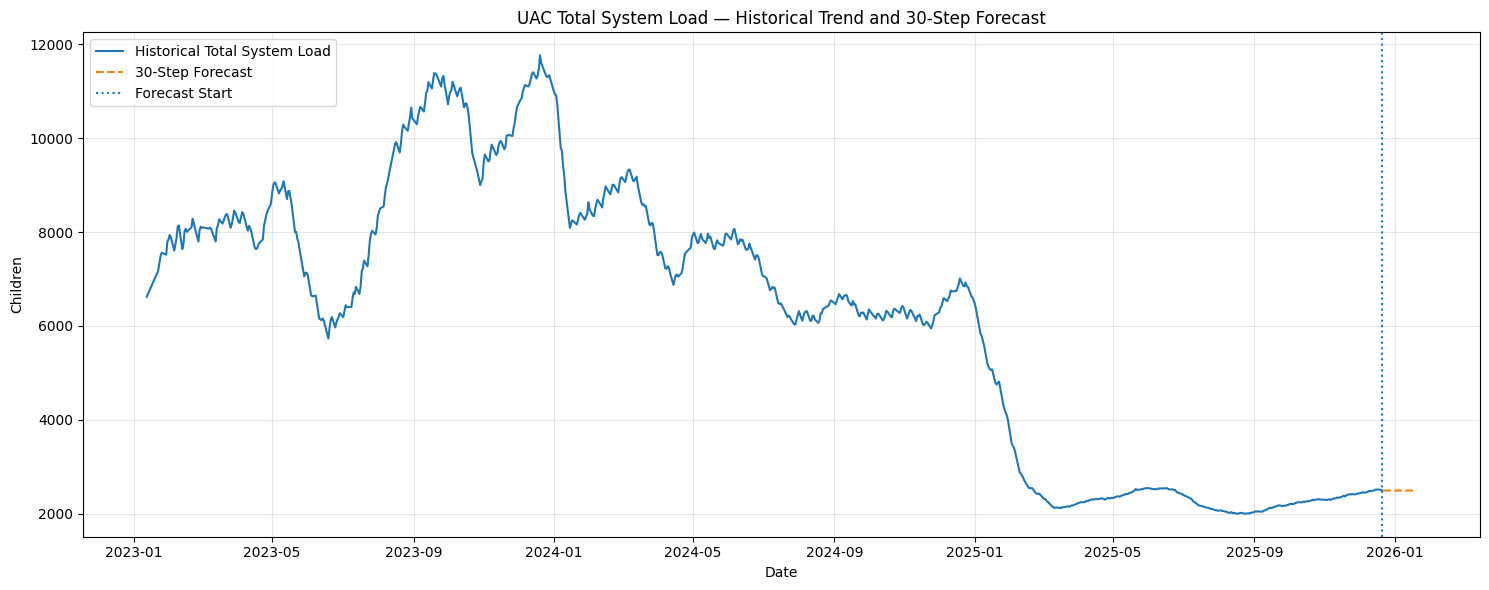

In [94]:
# STEP 29 — FINAL FORECAST VISUALIZATION

plt.figure(figsize=(15, 6))

# Historical observed system load
plt.plot(
    forecast_df["Date"],
    forecast_df["Total System Load"],
    label="Historical Total System Load"
)

# Forecast
plt.plot(
    forecast_output["Date"],
    forecast_output["Forecasted Total System Load"],
    linestyle="--",
    label="30-Step Forecast"
)

# Mark the point where forecasting begins
plt.axvline(
    forecast_df["Date"].max(),
    linestyle=":",
    label="Forecast Start"
)

plt.xlabel("Date")
plt.ylabel("Children")
plt.title("UAC Total System Load — Historical Trend and 30-Step Forecast")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

STEP 29A — Forecast Summary

In [95]:
# STEP 29A— FORECAST SUMMARY

print("FORECAST SUMMARY")
print("-" * 50)

print("Last observed date:",
      forecast_df["Date"].max().date())

print("First forecast date:",
      forecast_output["Date"].min().date())

print("Last forecast date:",
      forecast_output["Date"].max().date())

print("Average forecasted system load:",
      round(
          forecast_output["Forecasted Total System Load"].mean(),
          2
      ))

print("Minimum forecasted system load:",
      round(
          forecast_output["Forecasted Total System Load"].min(),
          2
      ))

print("Maximum forecasted system load:",
      round(
          forecast_output["Forecasted Total System Load"].max(),
          2
      ))

display(forecast_output.head(10))

FORECAST SUMMARY
--------------------------------------------------
Last observed date: 2025-12-21
First forecast date: 2025-12-22
Last forecast date: 2026-01-20
Average forecasted system load: 2497.46
Minimum forecasted system load: 2497.46
Maximum forecasted system load: 2497.54


,Date,Forecasted Total System Load
0,2025-12-22,2497.541462
1,2025-12-23,2497.461957
2,2025-12-24,2497.460539
3,2025-12-25,2497.460514
4,2025-12-26,2497.460513
5,2025-12-27,2497.460513
6,2025-12-28,2497.460513
7,2025-12-29,2497.460513
8,2025-12-30,2497.460513
9,2025-12-31,2497.460513


STEP 29B — Export the Forecast

In [96]:
# STEP 29B — EXPORT FINAL FORECAST

forecast_output.to_csv(
    "UAC_30_Day_System_Load_Forecast_Final.csv",
    index=False
)

print("Forecast exported successfully:")
print("UAC_30_Day_System_Load_Forecast_Final.csv")

Forecast exported successfully:
UAC_30_Day_System_Load_Forecast_Final.csv


STEP 30 — Create One Master Analysis Dataset

In [97]:
# STEP 30 — MASTER ANALYSIS DATASET

master_df = df_clean.copy()

# Sort chronologically
master_df = master_df.sort_values("Date").reset_index(drop=True)

# Save the complete analytical dataset
master_df.to_csv(
    "UAC_Master_Analysis_Dataset.csv",
    index=False
)

print("Master dataset created.")
print("Rows:", len(master_df))
print("Columns:", len(master_df.columns))

display(master_df.head())

Master dataset created.
Rows: 720
Columns: 20


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Total System Load,Net Intake Pressure,Care Load Growth Rate,7-Day Rolling Load,14-Day Rolling Load,Cumulative Net Intake,Discharge Offset Ratio,Month,High Load,Very High Load,Sustained High Load,Backlog Indicator,7-Observation Rolling Load,14-Observation Rolling Load
0,2023-01-12,33.0,53.0,34.0,6566,436.0,6619.0,-402.0,NaN,NaN,NaN,-402.0,12.823529,2023-01,False,False,False,-402.0,NaN,NaN
1,2023-01-22,32.0,49.0,39.0,7122,227.0,7171.0,-188.0,8.339628,NaN,NaN,-590.0,5.820513,2023-01,False,False,False,-590.0,NaN,NaN
2,2023-01-23,32.0,50.0,39.0,7280,181.0,7330.0,-142.0,2.217264,NaN,NaN,-732.0,4.641026,2023-01,False,False,False,-732.0,NaN,NaN
3,2023-01-24,47.0,42.0,47.0,7433,175.0,7475.0,-128.0,1.978172,NaN,NaN,-860.0,3.723404,2023-01,False,False,False,-860.0,NaN,NaN
4,2023-01-25,20.0,22.0,41.0,7538,180.0,7560.0,-139.0,1.137124,NaN,NaN,-999.0,4.390244,2023-01,False,False,False,-999.0,NaN,NaN


STEP 30A — Export All Important Analysis Tables

In [98]:
# STEP 30A — EXPORT ANALYSIS TABLES

results_summary.to_csv(
    "UAC_Final_Results_Summary.csv",
    index=False
)

monthly_analysis.to_csv(
    "UAC_Monthly_Analysis.csv",
    index=False
)

sustained_periods.to_csv(
    "UAC_Sustained_High_Load_Periods.csv",
    index=False
)

data_quality_summary.to_csv(
    "UAC_Data_Quality_Summary.csv",
    index=False
)

print("All major analysis tables exported successfully.")

All major analysis tables exported successfully.


STEP 31 — Final EDA Insight Extraction

In [99]:
# STEP 31 — FINAL EDA INSIGHT EXTRACTION

# --------------------------------------------------
# 1. Basic analysis period
# --------------------------------------------------

analysis_start = df_clean["Date"].min()
analysis_end = df_clean["Date"].max()

# --------------------------------------------------
# 2. System load statistics
# --------------------------------------------------

avg_load = df_clean["Total System Load"].mean()
min_load = df_clean["Total System Load"].min()
max_load = df_clean["Total System Load"].max()

p75_load = df_clean["Total System Load"].quantile(0.75)
p90_load = df_clean["Total System Load"].quantile(0.90)

peak_row = df_clean.loc[
    df_clean["Total System Load"].idxmax()
]

lowest_row = df_clean.loc[
    df_clean["Total System Load"].idxmin()
]

# --------------------------------------------------
# 3. Net intake statistics
# --------------------------------------------------

avg_net_intake = df_clean["Net Intake Pressure"].mean()

positive_days = (
    df_clean["Net Intake Pressure"] > 0
).sum()

negative_days = (
    df_clean["Net Intake Pressure"] < 0
).sum()

zero_days = (
    df_clean["Net Intake Pressure"] == 0
).sum()

# --------------------------------------------------
# 4. Transfers and discharges
# --------------------------------------------------

total_transfers = df_clean[
    "Children transferred out of CBP custody"
].sum()

total_discharges = df_clean[
    "Children discharged from HHS Care"
].sum()

discharge_ratio = (
    total_discharges / total_transfers
)

# --------------------------------------------------
# 5. Volatility
# --------------------------------------------------

volatility_index = (
    df_clean["Total System Load"].std()
    / df_clean["Total System Load"].mean()
)

# --------------------------------------------------
# 6. High-load periods
# --------------------------------------------------

high_load_threshold = p75_load

high_load_days = (
    df_clean["Total System Load"]
    >= high_load_threshold
).sum()

# --------------------------------------------------
# 7. Monthly comparison
# --------------------------------------------------

monthly_peak = monthly_analysis.loc[
    monthly_analysis["Average_Load"].idxmax()
]

monthly_lowest = monthly_analysis.loc[
    monthly_analysis["Average_Load"].idxmin()
]

# --------------------------------------------------
# 8. Print findings
# --------------------------------------------------

print("=" * 70)
print("FINAL EDA INSIGHTS")
print("=" * 70)

print("\n1. ANALYSIS PERIOD")
print(
    f"The dataset covers {analysis_start.date()} "
    f"to {analysis_end.date()}."
)

print("\n2. SYSTEM LOAD")
print(
    f"Average total system load: {avg_load:,.2f} children"
)

print(
    f"Minimum observed system load: {min_load:,.0f} "
    f"on {lowest_row['Date'].date()}"
)

print(
    f"Maximum observed system load: {max_load:,.0f} "
    f"on {peak_row['Date'].date()}"
)

print(
    f"75th percentile system load: {p75_load:,.2f}"
)

print(
    f"90th percentile system load: {p90_load:,.2f}"
)

print("\n3. NET INTAKE PRESSURE")
print(
    f"Average net intake pressure: {avg_net_intake:,.2f}"
)

print(
    f"Positive net intake days: {positive_days}"
)

print(
    f"Negative net intake days: {negative_days}"
)

print(
    f"Zero net intake days: {zero_days}"
)

print("\n4. TRANSFERS AND DISCHARGES")
print(
    f"Total CBP → HHS transfers: {total_transfers:,.0f}"
)

print(
    f"Total HHS discharges: {total_discharges:,.0f}"
)

print(
    f"Discharge offset ratio: {discharge_ratio:.2%}"
)

print("\n5. LOAD VOLATILITY")
print(
    f"Care load volatility index: {volatility_index:.4f}"
)

print("\n6. HIGH-LOAD CONDITIONS")
print(
    f"75th-percentile threshold: {high_load_threshold:,.2f}"
)

print(
    f"Number of high-load observations: {high_load_days}"
)

print("\n7. MONTHLY PATTERN")
print(
    f"Highest average monthly load: "
    f"{monthly_peak['Month']} "
    f"({monthly_peak['Average_Load']:,.2f})"
)

print(
    f"Lowest average monthly load: "
    f"{monthly_lowest['Month']} "
    f"({monthly_lowest['Average_Load']:,.2f})"
)

print("=" * 70)

FINAL EDA INSIGHTS

1. ANALYSIS PERIOD
The dataset covers 2023-01-12 to 2025-12-21.

2. SYSTEM LOAD
Average total system load: 6,232.77 children
Minimum observed system load: 2,002 on 2025-08-24
Maximum observed system load: 11,762 on 2023-12-20
75th percentile system load: 8,249.50
90th percentile system load: 9,920.90

3. NET INTAKE PRESSURE
Average net intake pressure: -44.74
Positive net intake days: 238
Negative net intake days: 475
Zero net intake days: 7

4. TRANSFERS AND DISCHARGES
Total CBP → HHS transfers: 92,641
Total HHS discharges: 124,853
Discharge offset ratio: 134.77%

5. LOAD VOLATILITY
Care load volatility index: 0.4682

6. HIGH-LOAD CONDITIONS
75th-percentile threshold: 8,249.50
Number of high-load observations: 180

7. MONTHLY PATTERN
Highest average monthly load: 2023-12 (11,255.26)
Lowest average monthly load: 2025-08 (2,026.90)


STEP 31A — Create a machine-readable Insights Table

In [100]:
# STEP 31A — STRUCTURED INSIGHTS TABLE

insights_table = pd.DataFrame({
    "Insight": [
        "Analysis Period",
        "Average System Load",
        "Minimum System Load",
        "Maximum System Load",
        "75th Percentile Load",
        "90th Percentile Load",
        "Average Net Intake Pressure",
        "Positive Net Intake Days",
        "Negative Net Intake Days",
        "Total CBP-to-HHS Transfers",
        "Total HHS Discharges",
        "Discharge Offset Ratio",
        "Care Load Volatility Index",
        "Highest Average Monthly Load",
        "Lowest Average Monthly Load"
    ],

    "Value": [
        f"{analysis_start.date()} to {analysis_end.date()}",
        round(avg_load, 2),
        round(min_load, 2),
        round(max_load, 2),
        round(p75_load, 2),
        round(p90_load, 2),
        round(avg_net_intake, 2),
        positive_days,
        negative_days,
        int(total_transfers),
        int(total_discharges),
        round(discharge_ratio * 100, 2),
        round(volatility_index, 4),
        monthly_peak["Month"],
        monthly_lowest["Month"]
    ]
})

display(insights_table)

insights_table.to_csv(
    "UAC_Final_Insights_Table.csv",
    index=False
)

,Insight,Value
0,Analysis Period,2023-01-12 to 2025-12-21
1,Average System Load,6232.77
2,Minimum System Load,2002.0
3,Maximum System Load,11762.0
4,75th Percentile Load,8249.5
5,90th Percentile Load,9920.9
6,Average Net Intake Pressure,-44.74
7,Positive Net Intake Days,238
8,Negative Net Intake Days,475
9,Total CBP-to-HHS Transfers,92641


STEP 32 — Early vs Late Timeline Comparison

In [101]:
# STEP 32 — EARLY vs MIDDLE vs LATE TIMELINE

timeline_df = df_clean.copy()

timeline_df["Timeline Period"] = pd.qcut(
    timeline_df["Date"].rank(method="first"),
    q=3,
    labels=["Early", "Middle", "Late"]
)

timeline_comparison = (
    timeline_df
    .groupby("Timeline Period", observed=True)
    .agg(
        Observations=("Date", "count"),
        Average_System_Load=("Total System Load", "mean"),
        Maximum_System_Load=("Total System Load", "max"),
        Average_Net_Intake=("Net Intake Pressure", "mean"),
        Average_CBP_Load=("Children in CBP custody", "mean"),
        Average_HHS_Load=("Children in HHS Care", "mean"),
        Total_Transfers=(
            "Children transferred out of CBP custody",
            "sum"
        ),
        Total_Discharges=(
            "Children discharged from HHS Care",
            "sum"
        )
    )
    .reset_index()
)

display(timeline_comparison)

,Timeline Period,Observations,Average_System_Load,Maximum_System_Load,Average_Net_Intake,Average_CBP_Load,Average_HHS_Load,Total_Transfers,Total_Discharges
0,Early,240,8889.041667,11762.0,-135.350000,196.666667,8692.375000,37070.0,69554.0
1,Middle,240,7216.712500,9327.0,13.604167,284.395833,6932.316667,51467.0,48202.0
2,Late,240,2592.554167,6610.0,-12.470833,33.420833,2559.133333,4104.0,7097.0


STEP 32A — Visualize the Timeline Comparison

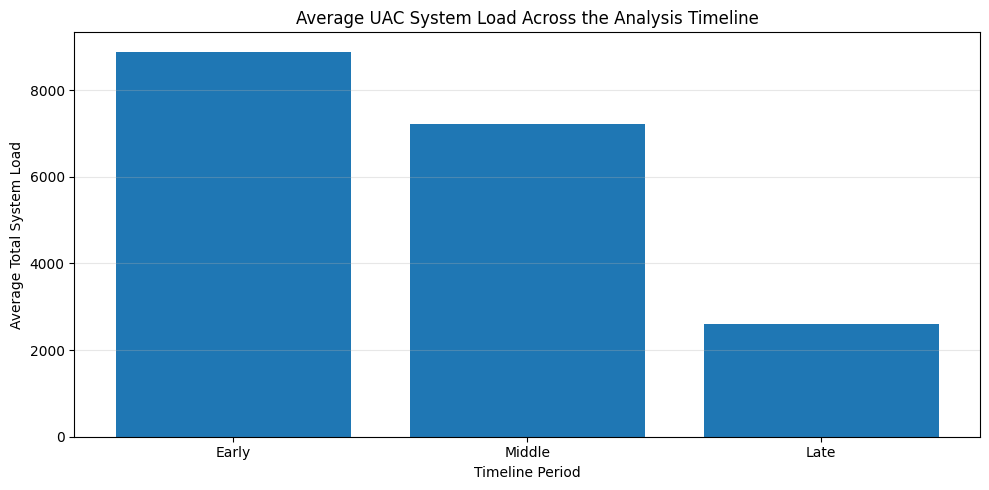

In [102]:
# STEP 32A — TIMELINE COMPARISON CHART

plt.figure(figsize=(10, 5))

plt.bar(
    timeline_comparison["Timeline Period"].astype(str),
    timeline_comparison["Average_System_Load"]
)

plt.xlabel("Timeline Period")
plt.ylabel("Average Total System Load")
plt.title("Average UAC System Load Across the Analysis Timeline")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

STEP 33 — KPI Dashboard Dataset

In [103]:
# STEP 33 — KPI DASHBOARD DATASET

kpi_dashboard = pd.DataFrame({
    "KPI": [
        "Average Total Children Under Care",
        "Average Net Intake Pressure",
        "Care Load Volatility Index",
        "Positive Net Intake Day Rate",
        "Discharge Offset Ratio",
        "Peak Total System Load",
        "Minimum Total System Load",
        "75th Percentile System Load",
        "90th Percentile System Load"
    ],

    "Value": [
        round(df_clean["Total System Load"].mean(), 2),
        round(df_clean["Net Intake Pressure"].mean(), 2),
        round(
            df_clean["Total System Load"].std()
            / df_clean["Total System Load"].mean(),
            4
        ),
        round(
            (df_clean["Net Intake Pressure"] > 0).mean() * 100,
            2
        ),
        round(
            (
                df_clean["Children discharged from HHS Care"].sum()
                /
                df_clean["Children transferred out of CBP custody"].sum()
            ) * 100,
            2
        ),
        int(df_clean["Total System Load"].max()),
        int(df_clean["Total System Load"].min()),
        round(df_clean["Total System Load"].quantile(0.75), 2),
        round(df_clean["Total System Load"].quantile(0.90), 2)
    ]
})

display(kpi_dashboard)

,KPI,Value
0,Average Total Children Under Care,6232.7700
1,Average Net Intake Pressure,-44.7400
2,Care Load Volatility Index,0.4682
3,Positive Net Intake Day Rate,33.0600
4,Discharge Offset Ratio,134.7700
5,Peak Total System Load,11762.0000
6,Minimum Total System Load,2002.0000
7,75th Percentile System Load,8249.5000
8,90th Percentile System Load,9920.9000


STEP 33A — Add KPI Definitions

In [104]:
# STEP 33A — KPI DEFINITIONS

kpi_definitions = pd.DataFrame({
    "KPI": [
        "Average Total Children Under Care",
        "Average Net Intake Pressure",
        "Care Load Volatility Index",
        "Positive Net Intake Day Rate",
        "Discharge Offset Ratio",
        "Peak Total System Load",
        "Minimum Total System Load",
        "75th Percentile System Load",
        "90th Percentile System Load"
    ],

    "Definition": [
        "Average daily combined CBP custody and HHS care population.",
        "Average daily transfers into HHS care minus HHS discharges.",
        "Standard deviation of total system load divided by its mean.",
        "Percentage of observed days where net intake pressure was positive.",
        "Total HHS discharges divided by total CBP-to-HHS transfers.",
        "Highest observed combined CBP and HHS population.",
        "Lowest observed combined CBP and HHS population.",
        "Load level at or below which 75% of observations fall.",
        "Load level at or below which 90% of observations fall."
    ]
})

display(kpi_definitions)

,KPI,Definition
0,Average Total Children Under Care,Average daily combined CBP custody and HHS car...
1,Average Net Intake Pressure,Average daily transfers into HHS care minus HH...
2,Care Load Volatility Index,Standard deviation of total system load divide...
3,Positive Net Intake Day Rate,Percentage of observed days where net intake p...
4,Discharge Offset Ratio,Total HHS discharges divided by total CBP-to-H...
5,Peak Total System Load,Highest observed combined CBP and HHS population.
6,Minimum Total System Load,Lowest observed combined CBP and HHS population.
7,75th Percentile System Load,Load level at or below which 75% of observatio...
8,90th Percentile System Load,Load level at or below which 90% of observatio...


STEP 33B — Export KPI Data

In [105]:
# STEP 33B — EXPORT KPI TABLES

kpi_dashboard.to_csv(
    "UAC_KPI_Dashboard.csv",
    index=False
)

kpi_definitions.to_csv(
    "UAC_KPI_Definitions.csv",
    index=False
)

print("KPI dashboard files exported successfully.")

KPI dashboard files exported successfully.


STEP 34 — Dashboard Time-Series Dataset

In [106]:
# STEP 34 — STREAMLIT TIME-SERIES DATASET

dashboard_timeseries = df_clean[
    [
        "Date",
        "Children in CBP custody",
        "Children transferred out of CBP custody",
        "Children in HHS Care",
        "Children discharged from HHS Care",
        "Total System Load",
        "Net Intake Pressure",
        "Care Load Growth Rate"
    ]
].copy()

dashboard_timeseries = dashboard_timeseries.sort_values(
    "Date"
).reset_index(drop=True)

display(dashboard_timeseries.head())

,Date,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Total System Load,Net Intake Pressure,Care Load Growth Rate
0,2023-01-12,53.0,34.0,6566,436.0,6619.0,-402.0,NaN
1,2023-01-22,49.0,39.0,7122,227.0,7171.0,-188.0,8.339628
2,2023-01-23,50.0,39.0,7280,181.0,7330.0,-142.0,2.217264
3,2023-01-24,42.0,47.0,7433,175.0,7475.0,-128.0,1.978172
4,2023-01-25,22.0,41.0,7538,180.0,7560.0,-139.0,1.137124


In [107]:
# STEP 34A — EXPORT DASHBOARD TIME SERIES

dashboard_timeseries.to_csv(
    "UAC_Dashboard_TimeSeries.csv",
    index=False
)

print("Dashboard time-series dataset exported.")

Dashboard time-series dataset exported.


STEP 35 — Create Weekly Aggregation

In [108]:
# STEP 35 — WEEKLY AGGREGATION

weekly_analysis = (
    df_clean
    .set_index("Date")
    .resample("W")
    .agg(
        Average_System_Load=("Total System Load", "mean"),
        Maximum_System_Load=("Total System Load", "max"),
        Minimum_System_Load=("Total System Load", "min"),
        Average_Net_Intake=("Net Intake Pressure", "mean"),
        Total_Transfers=(
            "Children transferred out of CBP custody",
            "sum"
        ),
        Total_Discharges=(
            "Children discharged from HHS Care",
            "sum"
        ),
        Observations=("Total System Load", "count")
    )
    .reset_index()
)

display(weekly_analysis.head(10))

,Date,Average_System_Load,Maximum_System_Load,Minimum_System_Load,Average_Net_Intake,Total_Transfers,Total_Discharges,Observations
0,2023-01-15,6619.00,6619.0,6619.0,-402.000000,34.0,436.0,1
1,2023-01-22,7171.00,7171.0,7171.0,-188.000000,39.0,227.0,1
2,2023-01-29,7470.50,7560.0,7330.0,-175.250000,138.0,839.0,4
3,2023-02-05,7813.40,7935.0,7604.0,-219.000000,130.0,1225.0,5
4,2023-02-12,7901.40,8142.0,7637.0,-169.600000,535.0,1383.0,5
5,2023-02-19,7958.75,8068.0,7742.0,-100.250000,717.0,1118.0,4
6,2023-02-26,8090.20,8281.0,7799.0,-75.600000,985.0,1363.0,5
7,2023-03-05,8084.00,8112.0,8039.0,-92.500000,720.0,1090.0,4
8,2023-03-12,8079.00,8093.0,8071.0,-140.333333,469.0,890.0,3
9,2023-03-19,8093.20,8269.0,7797.0,-73.000000,965.0,1330.0,5


STEP 35A — Weekly Load Chart

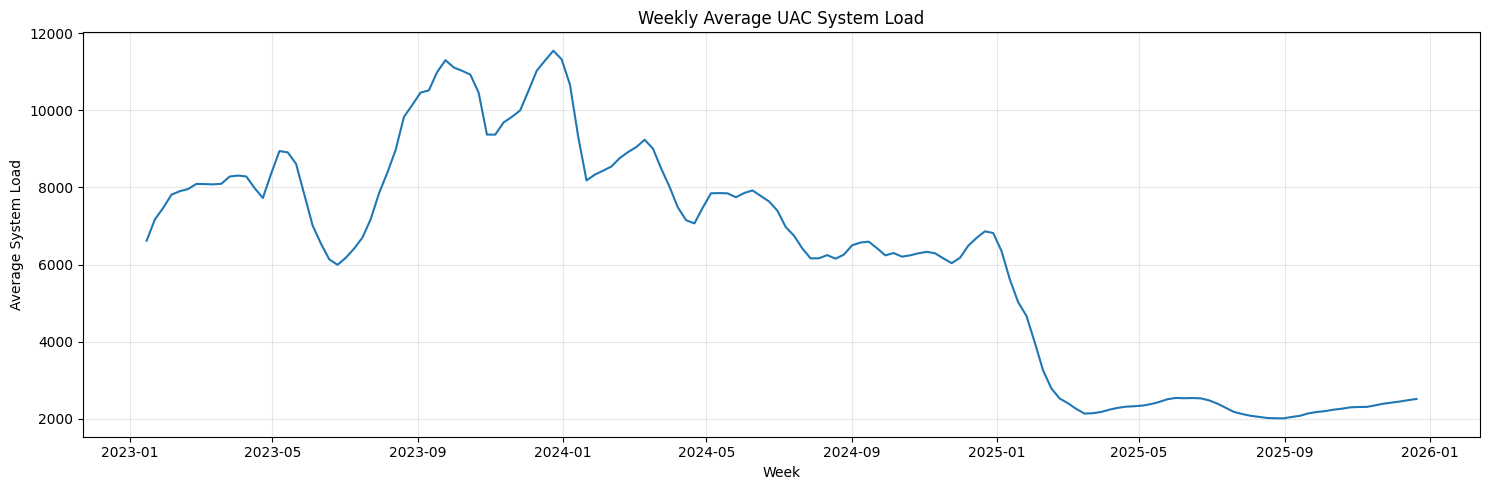

In [109]:
# STEP 35A — WEEKLY SYSTEM LOAD

plt.figure(figsize=(15, 5))

plt.plot(
    weekly_analysis["Date"],
    weekly_analysis["Average_System_Load"]
)

plt.xlabel("Week")
plt.ylabel("Average System Load")
plt.title("Weekly Average UAC System Load")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

STEP 36 — Save the Complete Dashboard Package

In [110]:
# STEP 36 — FINAL DASHBOARD DATA EXPORT

weekly_analysis.to_csv(
    "UAC_Weekly_Analysis.csv",
    index=False
)

monthly_analysis.to_csv(
    "UAC_Monthly_Analysis.csv",
    index=False
)

daily_df.to_csv(
    "UAC_Complete_Daily_Index.csv",
    index=False
)

print("=" * 60)
print("STREAMLIT DATA PACKAGE READY")
print("=" * 60)

print("\nFiles:")
print("1. UAC_Dashboard_TimeSeries.csv")
print("2. UAC_KPI_Dashboard.csv")
print("3. UAC_KPI_Definitions.csv")
print("4. UAC_Weekly_Analysis.csv")
print("5. UAC_Monthly_Analysis.csv")
print("6. UAC_Complete_Daily_Index.csv")

STREAMLIT DATA PACKAGE READY

Files:
1. UAC_Dashboard_TimeSeries.csv
2. UAC_KPI_Dashboard.csv
3. UAC_KPI_Definitions.csv
4. UAC_Weekly_Analysis.csv
5. UAC_Monthly_Analysis.csv
6. UAC_Complete_Daily_Index.csv


In [111]:
from google.colab import files
import glob
import os
import zipfile

# Find all CSV files created in the current Colab session
csv_files = glob.glob("*.csv")

print("CSV files found:")
for f in csv_files:
    print("-", f)

# Put all CSV files into one ZIP
with zipfile.ZipFile("UAC_Analysis_CSV_Files.zip", "w") as zipf:
    for f in csv_files:
        zipf.write(f)

# Download the ZIP
files.download("UAC_Analysis_CSV_Files.zip")

CSV files found:
- UAC_KPI_Dashboard.csv
- UAC_Master_Analysis_Dataset.csv
- UAC_Data_Quality_Summary.csv
- UAC_Sustained_High_Load_Periods.csv
- UAC_Final_Analytical_Dataset.csv
- UAC_Complete_Daily_Index.csv
- UAC_KPI_Definitions.csv
- UAC_Monthly_Analysis.csv
- UAC_Final_Results_Summary.csv
- UAC_Weekly_Analysis.csv
- HHS_Unaccompanied_Alien_Children_Program (1).csv
- UAC_30_Day_Forecast.csv
- UAC_Dashboard_TimeSeries.csv
- UAC_Final_Insights_Table.csv
- UAC_30_Day_System_Load_Forecast.csv
- UAC_30_Day_System_Load_Forecast_Final.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>